# Chunkwise CSE: exploratory data analysis

This notebook follows `Chunkwise_CSE_EDA_Plan.md`. It has two parts:

- **Part A: Screening** decides which annual reports can be used and how they should be chunked (steps A1 to A5, then a tier per report).
- **Part B: Exploratory analysis** informs the structure-aware chunker, the filtering rules and the section-specific prompts (steps B1 to B7).

Only narrative text and tables are analysed. Charts and infographics are out of scope.

**Sources.** Every report is read from its PDF text layer with PyMuPDF; the features are cached in `data/eda/cache` so later runs are fast. Where a report also has Docling JSON (in `data/extracted`, or in the Colab output folder `parse.import_dir` on Google Drive), the notebook uses Docling headings and tables as well. Steps that need Docling say so, and fall back to the PDF text layer when no Docling output is found.

**Outputs** go to `data/eda/` (git-ignored): `screening.csv`, `unmatched_headings.csv`, `boilerplate_passages.csv`, `sector_terms.csv` and `layout_changes.csv`. Hand-maintained inputs live in `data/reference/`: `company_metadata.csv` (tickers and GICS groups) and `ground_truth.csv` (hand-checked figures).

Run all cells from the top. The first run builds the cache (a few minutes per hundred reports); later runs only add new reports.

## 1. Setup and metadata table

In [1]:
import os
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

from docling_pipeline.config import load_config
from docling_pipeline.eda import plots
from docling_pipeline.eda.content import PAGE_CATEGORIES, page_categories, section_sizes
from docling_pipeline.eda.corpus import EXAMPLE_CHUNK_SIZE, profile_report, text_pass
from docling_pipeline.eda.docling_features import build_docling_cache, continuation_flags, index_docling_outputs, load_docling_features
from docling_pipeline.eda.ground_truth import compare_ground_truth, ground_truth_template, stratified_sample
from docling_pipeline.eda.metadata import build_metadata, company_of, load_company_metadata
from docling_pipeline.eda.pdf_features import STATEMENT_MIN_NUMBERS, build_cache, cache_paths, load_features
from docling_pipeline.eda.structure import NARRATIVE_TARGETS, SECTION_LABELS, TARGET_SECTIONS
from docling_pipeline.eda.textstats import distinctive_terms
from docling_pipeline.eda.timeline import layout_changes, section_order
from docling_pipeline.stages.parse import discover_reports

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
CONFIG = load_config(ROOT / "configs" / "extraction.yaml")
REPORTS_DIR = Path(CONFIG.data.reports_dir)
EDA_DIR = ROOT / "data" / "eda"
CACHE_DIR = EDA_DIR / "cache"
DOCLING_CACHE_DIR = EDA_DIR / "docling_cache"
REFERENCE_DIR = ROOT / "data" / "reference"
WORKERS = max(1, (os.cpu_count() or 2) - 1)
EXTRA_DOCLING_DIRS = [p for p in os.environ.get("EDA_DOCLING_DIRS", "").split(os.pathsep) if p]

EDA_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 120)
plots.apply_style()


def show_progress(done: int, total: int) -> None:
    """Print progress at every quarter of the work."""
    if done == total or done % max(1, total // 4) == 0:
        print(f"{done}/{total}", flush=True)

### Find the reports and build the PDF feature cache

Reports are discovered the same way as the extraction pipeline (`discover_reports`, skipping `parse.exclude_dirs`). Each report is opened once with PyMuPDF and its page features are cached. Reports that fail to open (for example a PDF still syncing from Drive) are listed and left out.

In [2]:
reports = discover_reports(REPORTS_DIR, CONFIG.parse.exclude_dirs)
cache_results = build_cache(reports, CACHE_DIR, workers=WORKERS, progress=show_progress)
cached = {rid: path for rid, path in reports.items() if cache_paths(CACHE_DIR, rid)[0].exists()}
cache_errors = pd.DataFrame([r for r in cache_results if r["status"] != "ok"], columns=["report_id", "status", "pages", "error"])
print(f"{len(reports)} PDFs found, {len(cache_results)} newly cached, {len(cached)} usable, {len(cache_errors)} failed to open")
cache_errors

1190 PDFs found, 0 newly cached, 1190 usable, 0 failed to open


,report_id,status,pages,error


### Docling output

Docling JSON is looked up in `data.extracted_dir`, in `parse.import_dir` (the Colab output on Google Drive) and in any folders listed in the `EDA_DOCLING_DIRS` environment variable. Its headings, tables and reading order are cached in `data/eda/docling_cache`.

In [3]:
docling_dirs = [ROOT / CONFIG.data.extracted_dir, *([Path(CONFIG.parse.import_dir)] if CONFIG.parse.import_dir else []), *map(Path, EXTRA_DOCLING_DIRS)]
docling_index: dict[str, Path] = {}
for folder in docling_dirs:
    for report_id, json_path in index_docling_outputs(folder).items():
        if report_id in cached:
            docling_index.setdefault(report_id, json_path)
docling_results = build_docling_cache(docling_index, DOCLING_CACHE_DIR, workers=WORKERS, progress=show_progress)
for failure in (r for r in docling_results if r["status"] != "ok"):
    docling_index.pop(failure["report_id"], None)
    print("Docling read failed:", failure["report_id"], failure["error"])
HAS_DOCLING = bool(docling_index)
for folder in docling_dirs:
    print(f"{'found  ' if folder.exists() else 'missing'} {folder}")
print(f"Docling output for {len(docling_index)} of {len(cached)} reports")


def docling_for(report_id: str) -> dict | None:
    """Return a report's cached Docling features, or None when it has no Docling output."""
    path = docling_index.get(report_id)
    return load_docling_features(path, DOCLING_CACHE_DIR) if path else None

missing C:\Users\hiruk\Desktop\Lectures\Year 2\DSGP\Benchmarking SLMs\Annual Report Docling Pipeline\data\extracted
missing G:\My Drive\chunkwise-cse\extracted_egret_large
Docling output for 0 of 1190 reports


### Master metadata table

One row per report. The company is the PDF's parent folder. GICS industry groups come from `data/reference/company_metadata.csv`; companies missing from that file are added with a sector guessed from the company name (`sector_source = name_rule`). Correct the guesses and fill in tickers by editing that file; existing rows are never overwritten.

**Core years** are the financial years that at least half of the companies have a report for. Charts and comparisons by year use only the core years, so a year with a handful of early reports does not show up as 0% or 100%.

In [4]:
companies = sorted({company_of(path, REPORTS_DIR) for path in cached.values()})
company_table = load_company_metadata(REFERENCE_DIR / "company_metadata.csv", companies)
meta = build_metadata(cached, REPORTS_DIR, company_table)
print(f"{len(meta)} reports from {meta['company'].nunique()} companies in {meta['gics_group'].nunique()} GICS groups; "
      f"{meta['year'].isna().sum()} reports have no year in the file name")
print("Sector source:", company_table["sector_source"].value_counts().to_dict())
year_share = meta.groupby("year")["company"].nunique() / meta["company"].nunique()
CORE_YEARS = [int(y) for y, share in year_share.items() if share >= 0.5]
print(f"Core years (at least half of the companies have a report): {CORE_YEARS}; "
      f"other years: {meta.loc[~meta['year'].isin(CORE_YEARS), 'year'].value_counts().to_dict()}")
meta.head()

1190 reports from 247 companies in 20 GICS groups; 0 reports have no year in the file name
Sector source: {'name_rule': 247}
Core years (at least half of the companies have a report): [2021, 2022, 2023, 2024, 2025]; other years: {np.int64(2026): 1}


,report_id,company,ticker,gics_group,year,file_path,file_size_mb
0,annual-report-2021,ABANS,,Retailing,2021,C:\Users\hiruk\Desktop\Lectures\Year 2\DSGP\Annual Reports\A\ABANS\Annual-Report-2021.pdf,15.19
1,abans-plc-annual-report-2021-22,ABANS,,Retailing,2022,C:\Users\hiruk\Desktop\Lectures\Year 2\DSGP\Annual Reports\A\ABANS\ABANS-PLC-Annual-Report-2021-22.pdf,2.26
2,abans-plc-annual-report-2022-23,ABANS,,Retailing,2023,C:\Users\hiruk\Desktop\Lectures\Year 2\DSGP\Annual Reports\A\ABANS\ABANS-PLC-Annual-Report-2022-23.pdf,5.80
3,abans_plc_annual_report_2023_24,ABANS,,Retailing,2024,C:\Users\hiruk\Desktop\Lectures\Year 2\DSGP\Annual Reports\A\ABANS\Abans_PLC_Annual_Report_2023_24.pdf,4.28
4,abans-plc-annual-report-fy24-25,ABANS,,Retailing,2025,C:\Users\hiruk\Desktop\Lectures\Year 2\DSGP\Annual Reports\A\ABANS\Abans-PLC-Annual-Report-FY24-25.pdf,3.61


### Profile every report

This loop runs steps A1 to A5 on each report (`profile_report`) and keeps the page-level measures used in Part B. It takes about a minute per thousand reports.

In [5]:
profiles, page_rows, size_rows, table_frames, density_rows = {}, [], [], [], []
for i, report_id in enumerate(meta["report_id"], 1):
    features = load_features(CACHE_DIR, report_id)
    docling = docling_for(report_id)
    profile = profile_report(features, docling)
    profiles[report_id] = {k: profile[k] for k in ("record", "sections", "segments", "unmatched", "statement_rows")}
    labels = page_categories(features, profile["sections"], profile["segments"])
    page_rows.extend({**{k: v for k, v in page.items() if k != "headings"}, "report_id": report_id, "category": label} for page, label in zip(features["pages"], labels))
    size_rows.extend({"report_id": report_id, **row} for row in section_sizes(features, profile["sections"]))
    numbers_by_page = {p["page"]: p["numbers"] for p in features["pages"]}
    table_pages = Counter(t["page"] for t in docling["tables"]) if docling else Counter()
    for key, section in profile["sections"].items():
        span = range(section["start"], section["end"] + 1)
        density_rows.append({
            "report_id": report_id, "section": key, "pages": len(span),
            "tables": sum(table_pages[p] for p in span) if docling else None,
            "figure_pages": sum(numbers_by_page.get(p, 0) >= STATEMENT_MIN_NUMBERS for p in span),
        })
    if docling and docling["tables"]:
        continued = {p["page"] for p in features["pages"] if p["continued"]}
        frame = pd.DataFrame(docling["tables"]).assign(report_id=report_id)
        table_frames.append(frame.assign(continues=continuation_flags(docling["tables"], continued)))
    show_progress(i, len(meta))

screen = meta.merge(pd.DataFrame([p["record"] for p in profiles.values()]), on="report_id")
sections = {rid: p["sections"] for rid, p in profiles.items()}
pages = pd.DataFrame(page_rows).merge(meta[["report_id", "gics_group", "year"]], on="report_id")
section_size = pd.DataFrame(size_rows).merge(meta[["report_id", "gics_group", "year"]], on="report_id")
section_density = pd.DataFrame(density_rows).merge(meta[["report_id", "gics_group"]], on="report_id")
tables = pd.concat(table_frames, ignore_index=True).merge(meta[["report_id", "gics_group"]], on="report_id") if table_frames else pd.DataFrame()
SECTOR_ORDER = list(screen["gics_group"].value_counts().index)
core = screen[screen["year"].isin(CORE_YEARS)]
FOUND_COLUMNS = [f"found_{key}" for key in TARGET_SECTIONS]
print(f"Profiled {len(screen)} reports, {len(pages):,} pages")

297/1190


594/1190


891/1190


1188/1190


1190/1190


Profiled 1190 reports, 210,622 pages


---
# Part A: Screening

## 2. A1 Text-based PDF check

A page is **image-only** when it has fewer than 50 extractable characters and images cover at least half of it. A report **passes** when at least 95% of its pages have text, is **partial** between 50% and 95%, and **fails** below 50% (a scan; OCR is out of scope).

Full-page photos and section dividers also count as image-only pages, so `partial` alone is not a problem. What matters is whether the image-only pages hit the financial statements; that is checked in A4. `chars_per_page` under about 200 matches the pipeline's "low text, possibly a scan" warning.

text_status,pass,partial,fail
reports,1131,50,9


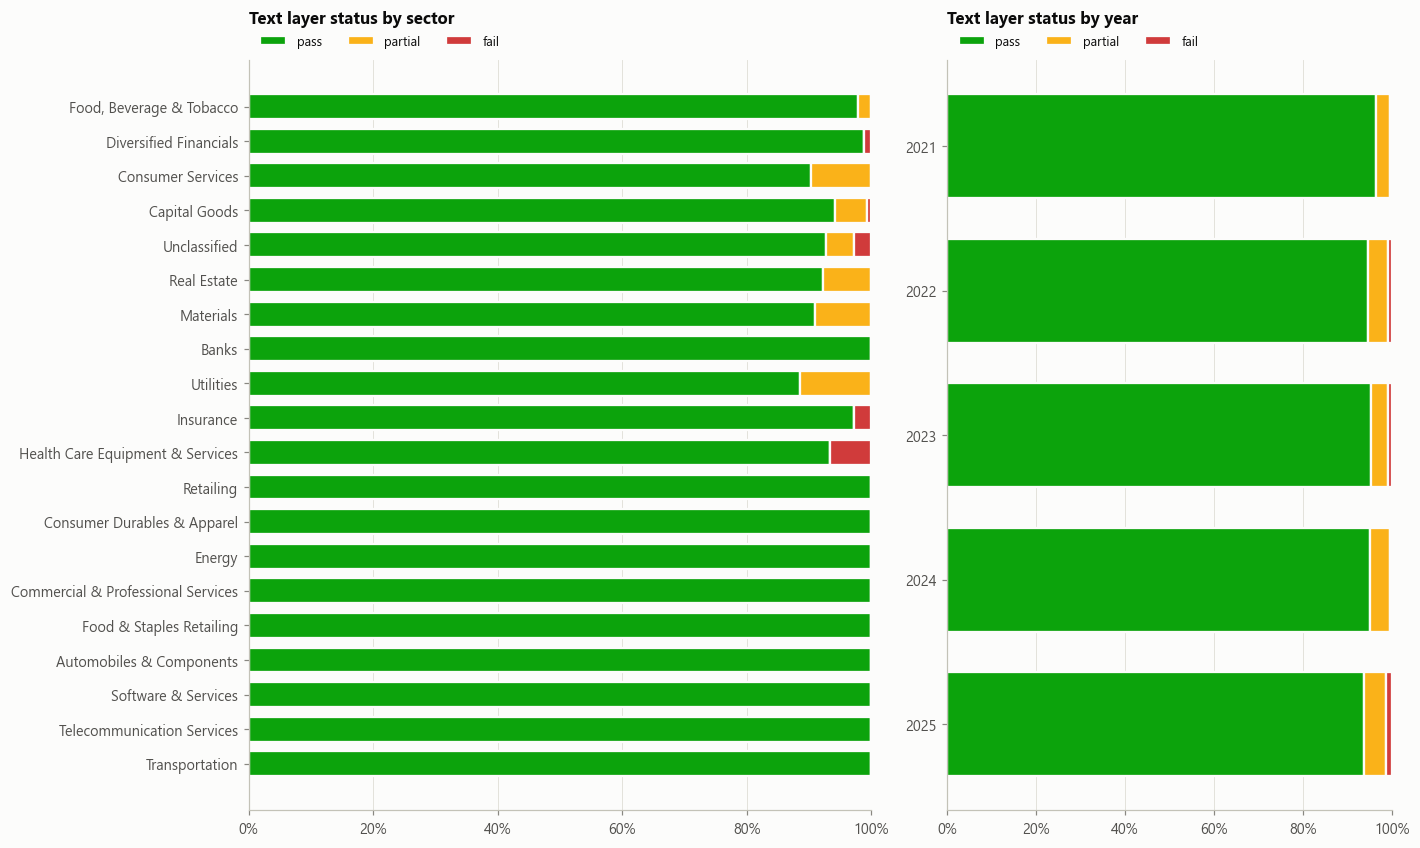

,report_id,company,year,page_count,text_page_ratio,chars_per_page,image_only_pages,text_status
40,alphafire_2022,ALPHA FIRE SERVICES,2022,53,0.000,0,1-53,fail
75,arpicoinsurance_2023,ARPICO INSURANCE,2023,262,0.000,0,1-262,fail
198,calfiveoptimum_2025,CAL FIVE YEAR OPTIMUM FUND,2025,43,0.000,0,1-43,fail
196,calfiveclosed_2025,CAL FIVE YEAR CLOSED END FUND,2025,40,0.000,0,1-40,fail
1052,singhe_2023,SINGHE HOSPITALS,2023,114,0.000,0,1-114,fail
1051,singhe_2022,SINGHE HOSPITALS,2022,114,0.000,0,1-114,fail
1134,tessagro_2025,TESS AGRO,2025,89,0.000,0,1-89,fail
1133,tessagro_2024,TESS AGRO,2024,95,0.000,0,1-95,fail
916,radiantgems_2021,RADIANT GEMS INTERNATIONAL,2021,59,0.034,130,"1-23, 25-30, 32-59",fail
808,myland_2022,MYLAND DEVELOPMENTS,2022,77,0.545,703,"32, 34-50, 52-54, 56-69",partial


In [6]:
TEXT_ORDER = ["pass", "partial", "fail"]
display(screen["text_status"].value_counts().reindex(TEXT_ORDER, fill_value=0).to_frame("reports").T)
fig, axes = plt.subplots(1, 2, figsize=(13, 0.3 * len(SECTOR_ORDER) + 1.8), width_ratios=[1.4, 1])
plots.stacked_share(pd.crosstab(screen["gics_group"], screen["text_status"]).reindex(index=SECTOR_ORDER, columns=TEXT_ORDER, fill_value=0),
                    plots.TEXT_STATUS_COLORS, "Text layer status by sector", ax=axes[0])
plots.stacked_share(pd.crosstab(core["year"], core["text_status"]).reindex(columns=TEXT_ORDER, fill_value=0),
                    plots.TEXT_STATUS_COLORS, "Text layer status by year", ax=axes[1])
plt.tight_layout()
plt.show()
screen.loc[screen["text_status"] != "pass", ["report_id", "company", "year", "page_count", "text_page_ratio", "chars_per_page", "image_only_pages", "text_status"]].sort_values("text_page_ratio")

## 3. A2 Heading hierarchy check

Docling does not read the PDF's table of contents, and its own headings are often flat, so each structure source is checked separately:

- **Bookmarks**: the PDF's embedded outline (at least 5 entries pointing to 5 different pages).
- **Contents page**: a printed contents page in the first 15 pages, aligned to real pages. Printed page numbers usually differ from PDF page numbers by a fixed offset; the offset is found by matching contents entries to large-font headings, and the page is usable when at least half of the entries line up.
- **Docling headings**: used when neither of the above works and Docling found at least 10 headings.
- **None**: fallback chunking rules apply.

structure_source,bookmarks,contents_page,docling_only,none
reports,98,955,0,137


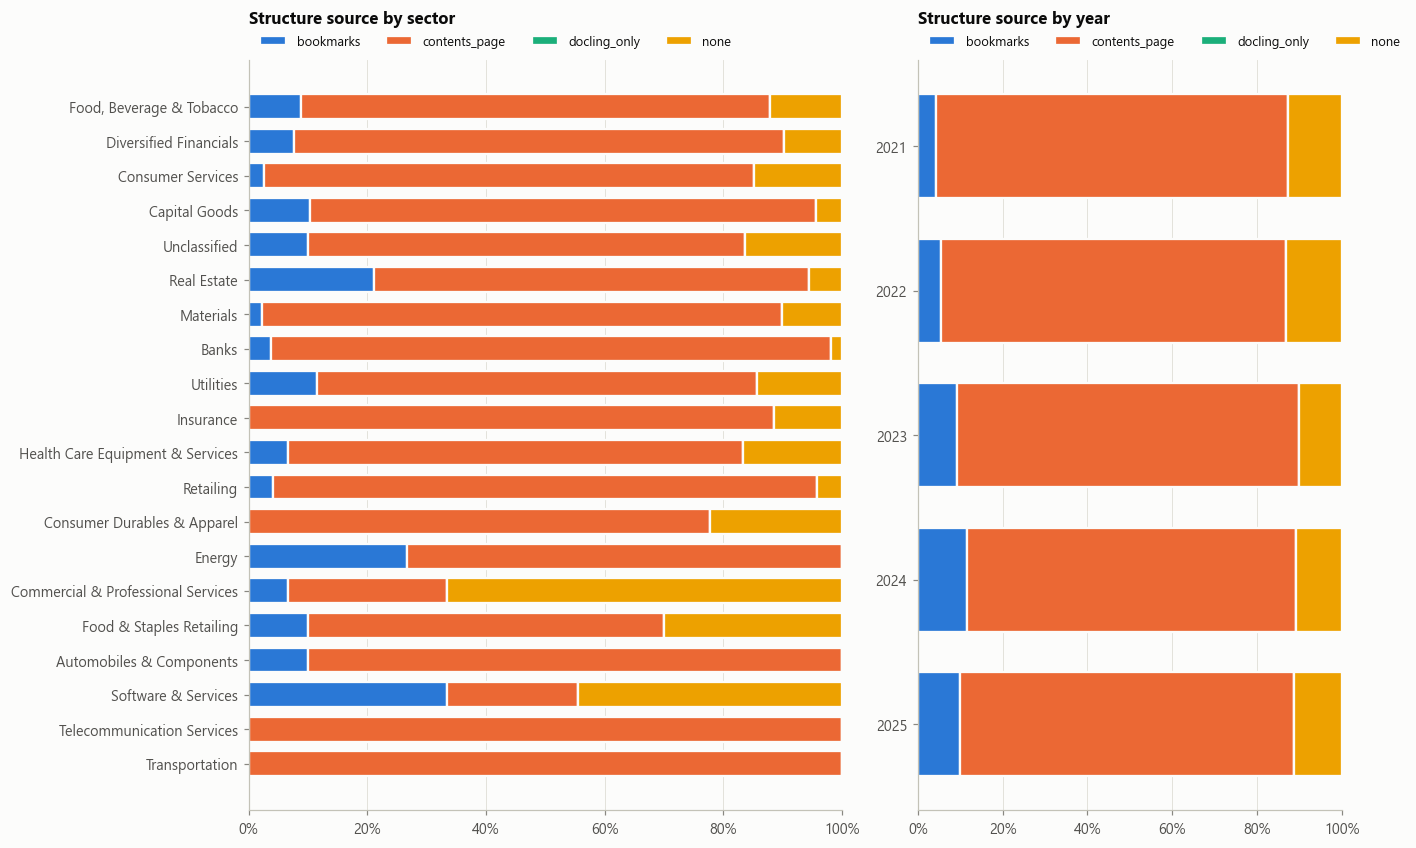

,value
Reports with usable bookmarks,8%
Reports with a printed contents page,89%
...of which aligned to real pages,97%
"Median bookmark depth (levels), when present",1
Most common printed-to-PDF page offsets,"+2 (804), +1 (137), +0 (54), +4 (31), +3 (10)"
Reports with Docling headings,0


In [7]:
SOURCES = ["bookmarks", "contents_page", "docling_only", "none"]
SOURCE_COLORS = dict(zip(SOURCES, plots.CATEGORICAL))
display(screen["structure_source"].value_counts().reindex(SOURCES, fill_value=0).to_frame("reports").T)
fig, axes = plt.subplots(1, 2, figsize=(13, 0.3 * len(SECTOR_ORDER) + 1.8), width_ratios=[1.4, 1])
plots.stacked_share(pd.crosstab(screen["gics_group"], screen["structure_source"]).reindex(index=SECTOR_ORDER, columns=SOURCES, fill_value=0),
                    SOURCE_COLORS, "Structure source by sector", ax=axes[0])
plots.stacked_share(pd.crosstab(core["year"], core["structure_source"]).reindex(columns=SOURCES, fill_value=0),
                    SOURCE_COLORS, "Structure source by year", ax=axes[1])
plt.tight_layout()
plt.show()
with_contents = screen[screen["has_contents_page"]]
structure_summary = pd.Series({
    "Reports with usable bookmarks": f"{screen['has_bookmarks'].mean():.0%}",
    "Reports with a printed contents page": f"{screen['has_contents_page'].mean():.0%}",
    "...of which aligned to real pages": f"{(with_contents['contents_aligned_share'] >= 0.5).mean():.0%}",
    "Median bookmark depth (levels), when present": f"{screen.loc[screen['has_bookmarks'], 'bookmark_levels'].median():.0f}",
    "Most common printed-to-PDF page offsets": ", ".join(f"{int(k):+d} ({v})" for k, v in screen["page_offset"].value_counts().head(5).items()),
    "Reports with Docling headings": f"{screen['has_docling'].sum()}",
}, name="value")
structure_summary.to_frame()

## 4. A3 Target section coverage

Headings from the structure source chosen in A2 are fuzzy-matched (score 85 or more) against the synonym map in `structure.TARGET_SECTIONS`. Each matched section gets a start and end page. For heading-based sources, statements are only accepted after the first 15% of pages, so highlight pages such as "Balance sheet highlights" are not mistaken for the statements.

Review the unmatched headings below (also saved to `data/eda/unmatched_headings.csv`) and add new variants to the synonym map.

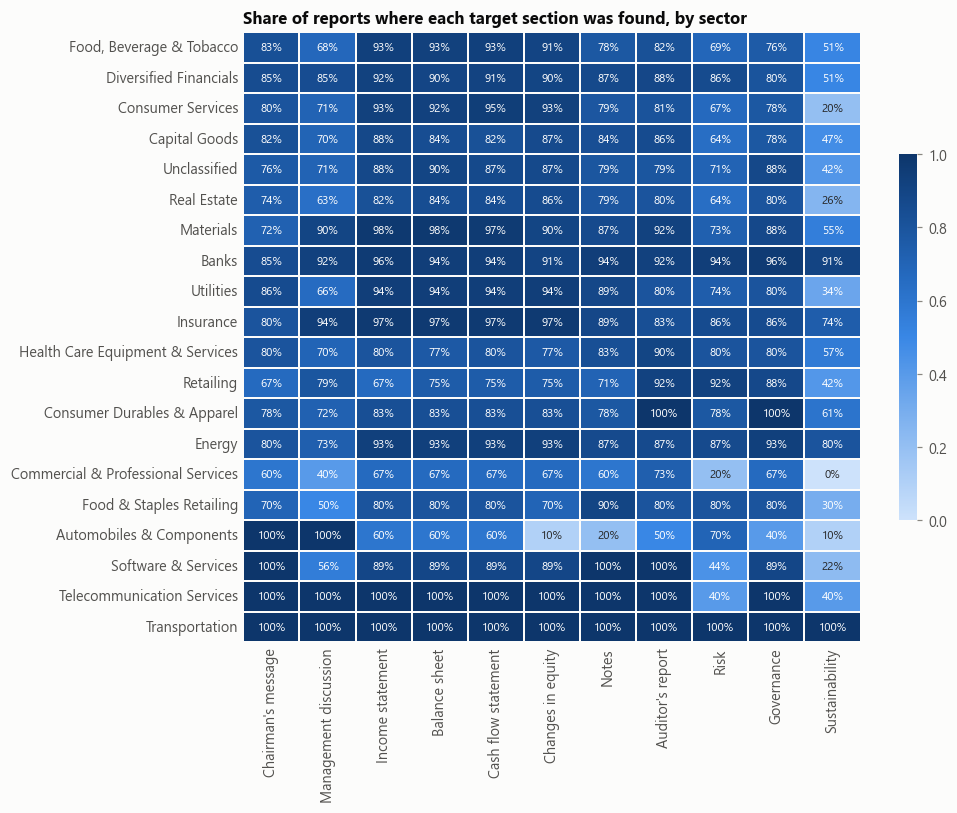

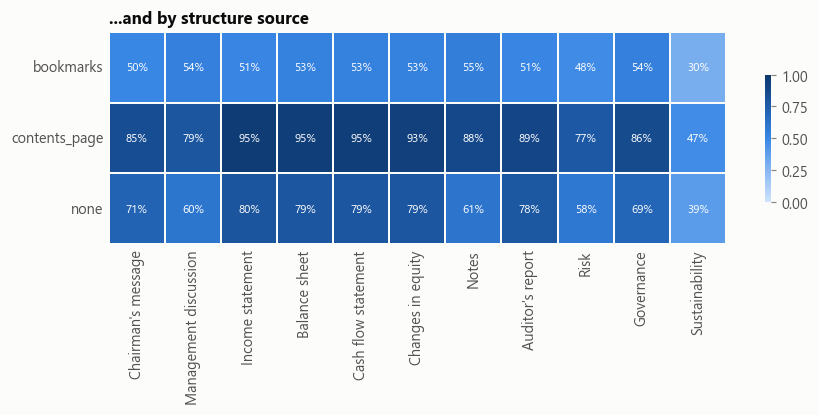

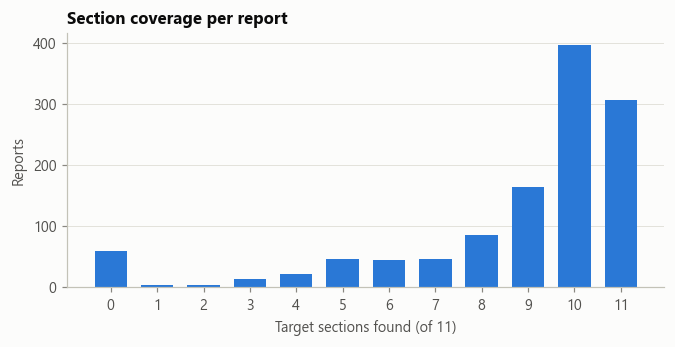

,normalised heading,reports
0,board of directors,808
1,form of proxy,774
2,notice of meeting,730
3,audit committee report,541
4,financial highlights,460
5,corporate information,459
6,remuneration committee report,423
7,financial calendar,362
8,human capital,361
9,intellectual capital,352


In [8]:
SECTION_NAMES = [SECTION_LABELS[k] for k in TARGET_SECTIONS]
coverage_by_sector = screen.groupby("gics_group")[FOUND_COLUMNS].mean().reindex(SECTOR_ORDER).set_axis(SECTION_NAMES, axis=1)
plots.heatmap(coverage_by_sector, "Share of reports where each target section was found, by sector", vmax=1)
plt.show()
coverage_by_source = screen.groupby("structure_source")[FOUND_COLUMNS].mean().reindex([s for s in SOURCES if s in set(screen["structure_source"])]).set_axis(SECTION_NAMES, axis=1)
plots.heatmap(coverage_by_source, "...and by structure source", vmax=1)
plt.show()
fig, ax = plt.subplots(figsize=(7, 3))
coverage_counts = screen["section_coverage"].value_counts().reindex(range(len(TARGET_SECTIONS) + 1), fill_value=0)
ax.bar(coverage_counts.index, coverage_counts.values, color=plots.CATEGORICAL[0], width=0.7)
ax.set_xticks(coverage_counts.index)
ax.set_xlabel(f"Target sections found (of {len(TARGET_SECTIONS)})")
ax.set_ylabel("Reports")
ax.grid(axis="x", visible=False)
ax.set_title("Section coverage per report")
plt.show()
unmatched = Counter(h for p in profiles.values() for h in set(p["unmatched"]) if h)
unmatched_table = pd.DataFrame(unmatched.most_common(), columns=["normalised heading", "reports"])
unmatched_table.to_csv(EDA_DIR / "unmatched_headings.csv", index=False)
unmatched_table.head(40)

## 5. A4 Table extractability

For every Docling table: rows, columns, the share of empty cells, the **numeric parse rate** (the share of body cells containing a digit that parse as accounting figures, handling `(1,234)` negatives, `-` for nil and unit labels such as `Rs. '000`), and row consistency.

A financial statement pasted as an image is the main trap. A statement is flagged when it was located (by heading or by its figures) but none of its pages holds a Docling table. Without Docling output, a statement is flagged when its heading was found but the text layer has no page with statement figures.

In [9]:
if HAS_DOCLING:
    table_columns = ["table_count", "mean_numeric_parse_rate", "empty_cell_ratio", "row_consistency", "multi_page_tables"]
    display(screen.loc[screen["has_docling"], table_columns].describe().T.round(3))
    with_rate = screen[screen["has_docling"] & screen["mean_numeric_parse_rate"].notna()]
    fig, ax = plt.subplots(figsize=(9, 0.3 * with_rate["gics_group"].nunique() + 1.5))
    sns.boxplot(data=with_rate, y="gics_group", x="mean_numeric_parse_rate", order=[s for s in SECTOR_ORDER if s in set(with_rate["gics_group"])],
                color=plots.SEQUENTIAL_STEPS[2], linewidth=1, fliersize=3, ax=ax)
    ax.set_xlabel("Numeric parse rate (digit cells that parse as figures)")
    ax.set_ylabel("")
    ax.set_title("Numeric parse rate of Docling tables by sector")
    plt.show()
else:
    display(Markdown("**No Docling output found**, so table metrics are not available yet. Import the Colab output "
                     "(`docling-pipeline run`) or connect Google Drive, then rerun from the top. The image-statement flags "
                     "below use the PDF text layer."))
image_flags = screen.loc[screen["image_statement_flag"], ["report_id", "company", "year", "text_status", "image_statements", "image_only_pages"]]
print(f"{len(image_flags)} reports have a statement that looks like an image "
      f"({screen['image_statements'].explode().value_counts().to_dict()})")
image_flags

**No Docling output found**, so table metrics are not available yet. Import the Colab output (`docling-pipeline run`) or connect Google Drive, then rerun from the top. The image-statement flags below use the PDF text layer.

32 reports have a statement that looks like an image ({'changes_in_equity': 24, 'cash_flow': 13, 'income_statement': 4, 'balance_sheet': 3})


,report_id,company,year,text_status,image_statements,image_only_pages
69,anilana_2021,ANILANA HOTELS AND PROPERTIES,2021,partial,"[income_statement, cash_flow, changes_in_equity]","1-3, 12, 14, 16-17, 20-21, 25-27, 33, 56-57, 63, 115-116"
71,anilana_2023,ANILANA HOTELS AND PROPERTIES,2023,partial,"[income_statement, cash_flow, changes_in_equity]","1-3, 12, 14, 16-17, 20-21, 25-27, 31, 33, 51-53, 59, 111-112"
72,anilana_2024,ANILANA HOTELS AND PROPERTIES,2024,pass,"[income_statement, cash_flow, changes_in_equity]","1, 92"
80,asiaassetfinance_2023,ASIA ASSET FINANCE,2023,pass,[cash_flow],
84,asiacapital_2022,ASIA CAPITAL,2022,pass,[changes_in_equity],
117,bairaha_2025,BAIRAHA FARMS,2025,pass,[cash_flow],1
243,ceyloncoldstores_2022,CEYLON COLD STORES,2022,pass,[changes_in_equity],
244,ceyloncoldstores_2023,CEYLON COLD STORES,2023,pass,[changes_in_equity],
275,ceylonland_2024,CEYLON LAND & EQUITY,2024,pass,[income_statement],
294,chevron_2023,CHEVRON LUBRICANTS LANKA,2023,pass,[changes_in_equity],1-2


## 6. A5 Extraction correctness

### Automatic accounting checks

| Check | Rule |
|---|---|
| Balance sheet identity | Total assets = total equity + total liabilities |
| Subtotals | Line items sum to their stated subtotals (passes when at least 80% reconcile) |
| Cross-statement | Profit for the year matches across the income statement and the statement of changes in equity |
| Highlights | Current-year revenue or profit appears on the financial highlights pages |

Amounts may differ by 0.1% or 2 units for rounding. The checks run on the statement rows rebuilt from the **PDF text layer** for every report, and on the **Docling tables** where Docling output exists. The PDF-layer result shows whether a statement can be read at all; the Docling result is what the pipeline will actually use.

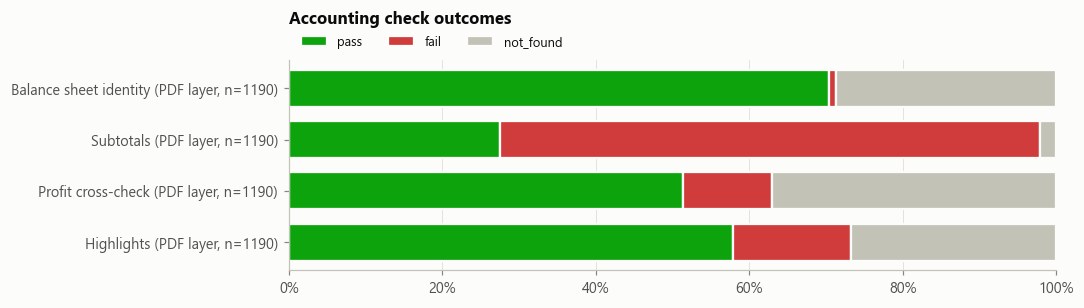

,pass,fail,not_found
"Balance sheet identity (PDF layer, n=1190)",838,11,341
"Subtotals (PDF layer, n=1190)",328,837,25
"Profit cross-check (PDF layer, n=1190)",611,138,441
"Highlights (PDF layer, n=1190)",689,182,319


In [10]:
CHECKS = {"bs_identity": "Balance sheet identity", "subtotal_rate": "Subtotals", "profit_cross_check": "Profit cross-check", "highlights_check": "Highlights"}
OUTCOME_COLORS = {"pass": plots.STATUS["good"], "fail": plots.STATUS["critical"], "not_found": plots.INK["axis"]}
outcomes = {}
for prefix, subset in [("PDF layer", screen), ("Docling", screen[screen["has_docling"]])]:
    if subset.empty:
        continue
    column_prefix = "pdf" if prefix == "PDF layer" else "docling"
    for key, label in CHECKS.items():
        values = subset[f"{column_prefix}_{key}"]
        if key == "subtotal_rate":
            values = values.map(lambda rate: "not_found" if pd.isna(rate) else ("pass" if rate >= 0.8 else "fail"))
        outcomes[f"{label} ({prefix}, n={len(subset)})"] = values.value_counts()
outcome_table = pd.DataFrame(outcomes).T.reindex(columns=list(OUTCOME_COLORS)).fillna(0)
plots.stacked_share(outcome_table, OUTCOME_COLORS, "Accounting check outcomes")
plt.show()
display(outcome_table.astype(int))

### Manual ground truth

A stratified sample of 2 reports per GICS group (different companies and years) is written once to `data/reference/ground_truth.csv`. For each sampled report, record by hand from the PDF:

- the key figures (`revenue`, `profit_before_tax`, `profit_for_year`, `eps_basic`, `total_assets`, `total_equity`, `total_liabilities`, `net_cash_operating`, `cash_at_end`) for the current year, in the units the statement uses (for example `Rs. '000`), with negatives as `-1234`;
- the **PDF page** (not the printed page) where each target section starts, in the `section_start:*` rows.

Leave a cell empty if the report does not have that item. The file is never overwritten, so rerunning the notebook keeps your entries. The comparison below names each mismatch: a lost negative sign, a unit mismatch (a factor of 1,000 or 1,000,000), a column shift (the value matches another column of the same row, often the prior year), or a wrong value.

In [11]:
GROUND_TRUTH = REFERENCE_DIR / "ground_truth.csv"
if not GROUND_TRUTH.exists():
    ground_truth_template(stratified_sample(meta)).to_csv(GROUND_TRUTH, index=False)
    print(f"Wrote a blank ground-truth sheet to {GROUND_TRUTH.relative_to(ROOT)}")
truth = pd.read_csv(GROUND_TRUTH, dtype=str).fillna("")
truth = truth[truth["report_id"].isin(profiles)]
comparison = compare_ground_truth(truth, {rid: p["statement_rows"] for rid, p in profiles.items()}, sections)
print(f"{truth['report_id'].nunique()} sampled reports, {len(comparison)} of {len(truth)} values filled in")
if comparison.empty:
    display(Markdown("No hand-checked values yet. Fill in `data/reference/ground_truth.csv` and rerun this cell."))
else:
    figures = comparison[comparison["kind"] == "figure"]
    section_rows = comparison[comparison["kind"] == "section"]
    display(pd.Series({
        "Section detection recall (start within 1 page)": f"{(section_rows['result'] == 'match').mean():.0%} of {len(section_rows)}" if len(section_rows) else "n/a",
        "Numeric match rate": f"{(figures['result'] == 'match').mean():.0%} of {len(figures)}" if len(figures) else "n/a",
    }, name="value").to_frame())
    display(pd.crosstab(comparison["result"], comparison["kind"]))
    display(comparison[comparison["result"] != "match"].sort_values(["report_id", "figure"]))

38 sampled reports, 0 of 760 values filled in


No hand-checked values yet. Fill in `data/reference/ground_truth.csv` and rerun this cell.

## 7. Screening table and tiers

| Tier | Criteria | Pipeline treatment |
|---|---|---|
| A | Text-based, reliable structure (bookmarks or an aligned contents page), the income statement, balance sheet and cash flow statement located, and tables that pass the checks | Main structure-aware pipeline |
| B | Text-based, but weak structure, a statement not located, or table checks failed or unverified | Fallback chunking rules |
| C | Scanned, or a core statement is an image | Excluded and counted |

"Tables that pass the checks" means a numeric parse rate of at least 90% and at least half of the accounting checks passing when Docling output exists, and at least half of the accounting checks passing on the PDF text layer otherwise. The `check_evidence` column says which was used. The full table is saved to `data/eda/screening.csv`.

**Final dataset: 1166 of 1190 reports** enter the pipeline (891 tier A, 275 tier B); **24 are excluded**. Tier evidence: {'pdf_layer': 1190}.

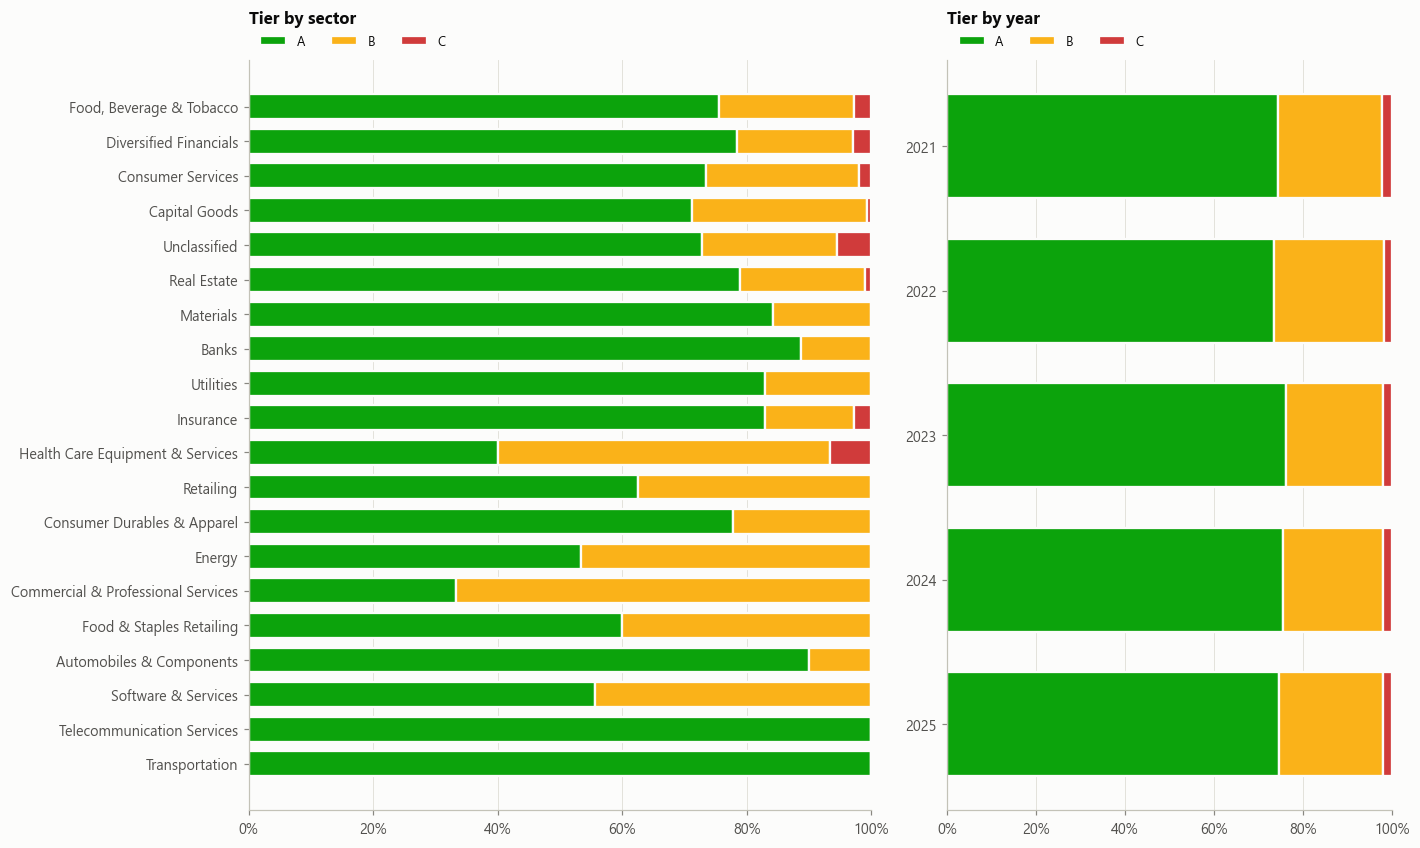

,tier,reason,reports
1,B,table checks failed,163
3,B,weak structure (none),122
2,B,table quality unverified,9
0,B,core statements not all located,7
4,C,mostly image-only pages (scanned),9
7,C,statement is an image: cash_flow,8
9,C,"statement is an image: income_statement, cash_flow",3
6,C,"statement is an image: balance_sheet, cash_flow",2
5,C,statement is an image: balance_sheet,1
8,C,statement is an image: income_statement,1


tier,A,B,C,total
gics_group,,,,
"Food, Beverage & Tobacco",136,39,5,180
Diversified Financials,135,32,5,172
Consumer Services,113,38,3,154
Capital Goods,96,38,1,135
Unclassified,80,24,6,110
Real Estate,71,18,1,90
Materials,75,14,0,89
Banks,47,6,0,53
Utilities,29,6,0,35


,report_id,company,year,tier_reasons
40,alphafire_2022,ALPHA FIRE SERVICES,2022,mostly image-only pages (scanned)
69,anilana_2021,ANILANA HOTELS AND PROPERTIES,2021,"statement is an image: income_statement, cash_flow"
71,anilana_2023,ANILANA HOTELS AND PROPERTIES,2023,"statement is an image: income_statement, cash_flow"
72,anilana_2024,ANILANA HOTELS AND PROPERTIES,2024,"statement is an image: income_statement, cash_flow"
75,arpicoinsurance_2023,ARPICO INSURANCE,2023,mostly image-only pages (scanned)
80,asiaassetfinance_2023,ASIA ASSET FINANCE,2023,statement is an image: cash_flow
117,bairaha_2025,BAIRAHA FARMS,2025,statement is an image: cash_flow
196,calfiveclosed_2025,CAL FIVE YEAR CLOSED END FUND,2025,mostly image-only pages (scanned)
198,calfiveoptimum_2025,CAL FIVE YEAR OPTIMUM FUND,2025,mostly image-only pages (scanned)
275,ceylonland_2024,CEYLON LAND & EQUITY,2024,statement is an image: income_statement


In [12]:
TIERS = ["A", "B", "C"]
tier_counts = screen["tier"].value_counts().reindex(TIERS, fill_value=0)
included = tier_counts["A"] + tier_counts["B"]
display(Markdown(f"**Final dataset: {included} of {len(screen)} reports** enter the pipeline "
                 f"({tier_counts['A']} tier A, {tier_counts['B']} tier B); **{tier_counts['C']} are excluded**. "
                 f"Tier evidence: {screen['check_evidence'].value_counts().to_dict()}."))
fig, axes = plt.subplots(1, 2, figsize=(13, 0.3 * len(SECTOR_ORDER) + 1.8), width_ratios=[1.4, 1])
plots.stacked_share(pd.crosstab(screen["gics_group"], screen["tier"]).reindex(index=SECTOR_ORDER, columns=TIERS, fill_value=0),
                    plots.TIER_COLORS, "Tier by sector", ax=axes[0])
plots.stacked_share(pd.crosstab(core["year"], core["tier"]).reindex(columns=TIERS, fill_value=0),
                    plots.TIER_COLORS, "Tier by year", ax=axes[1])
plt.tight_layout()
plt.show()
reasons = screen.loc[screen["tier"] != "A", ["tier", "tier_reasons"]].assign(reason=lambda d: d["tier_reasons"].str.split("; ")).explode("reason")
display(reasons.groupby(["tier", "reason"]).size().rename("reports").reset_index().sort_values(["tier", "reports"], ascending=[True, False]))
tier_table = pd.crosstab(screen["gics_group"], screen["tier"]).reindex(index=SECTOR_ORDER, columns=TIERS, fill_value=0)
display(tier_table.assign(total=tier_table.sum(axis=1)))
screen.assign(image_statements=screen["image_statements"].str.join(", ")).to_csv(EDA_DIR / "screening.csv", index=False)
screen.loc[screen["tier"] == "C", ["report_id", "company", "year", "tier_reasons"]]

---
# Part B: Exploratory analysis

## 8. B1 Corpus overview

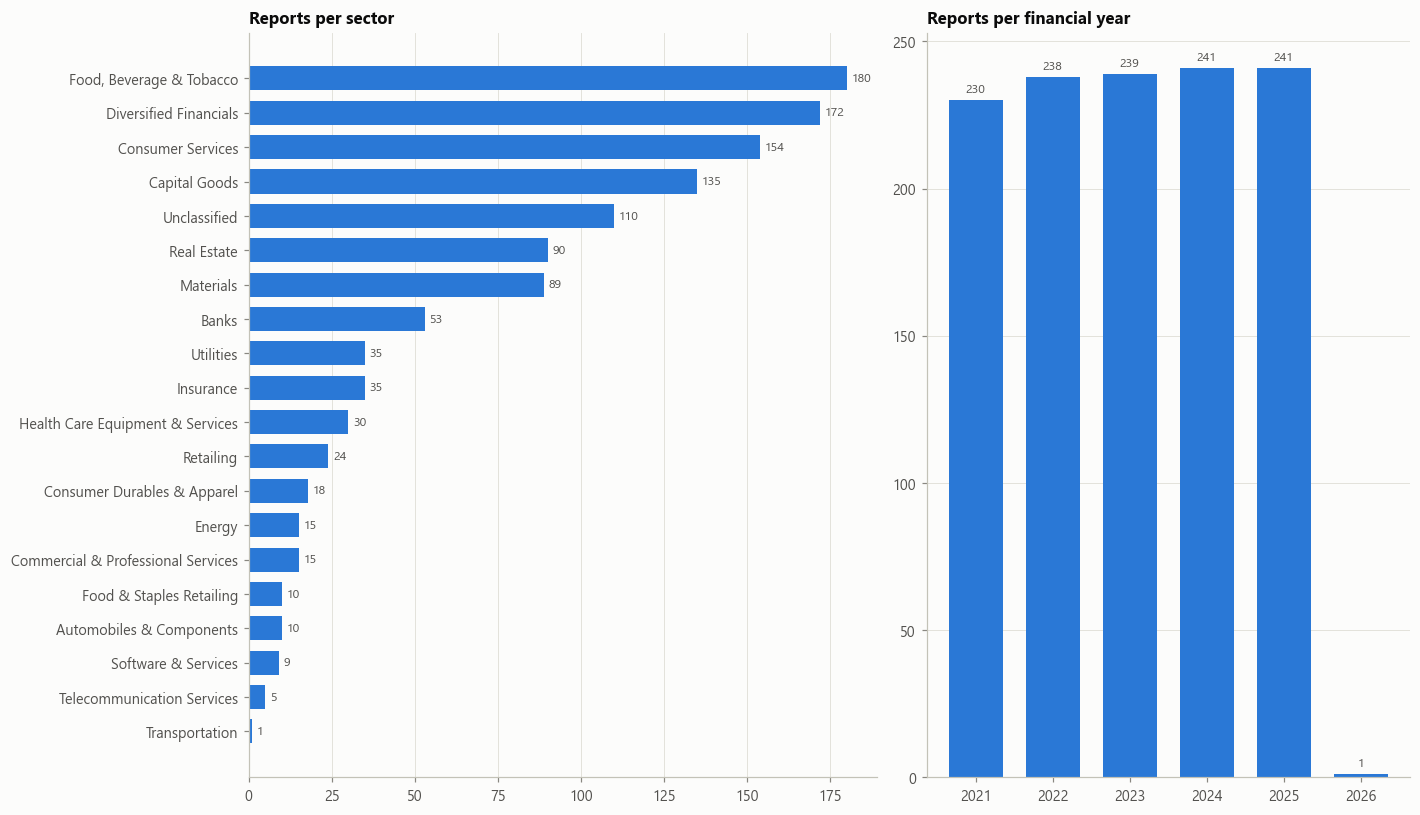

,reports,companies,median_pages,median_mb
gics_group,,,,
"Food, Beverage & Tobacco",180,37,141.0,4.580
Diversified Financials,172,38,216.0,4.500
Consumer Services,154,31,104.0,2.640
Capital Goods,135,28,192.0,4.330
Unclassified,110,22,136.0,3.920
Real Estate,90,19,116.0,3.620
Materials,89,18,143.0,3.230
Banks,53,11,348.0,7.420
Utilities,35,7,112.0,4.250


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 0.3 * len(SECTOR_ORDER) + 1.5), width_ratios=[1.3, 1])
sector_counts = screen["gics_group"].value_counts().reindex(SECTOR_ORDER)
axes[0].barh(sector_counts.index, sector_counts.values, color=plots.CATEGORICAL[0], height=0.7)
axes[0].bar_label(axes[0].containers[0], padding=3, fontsize=8, color=plots.INK["secondary"])
axes[0].invert_yaxis()
axes[0].grid(axis="y", visible=False)
axes[0].set_title("Reports per sector")
year_counts = screen["year"].value_counts().sort_index()
axes[1].bar(year_counts.index.astype(str), year_counts.values, color=plots.CATEGORICAL[0], width=0.7)
axes[1].bar_label(axes[1].containers[0], padding=3, fontsize=8, color=plots.INK["secondary"])
axes[1].grid(axis="x", visible=False)
axes[1].set_title("Reports per financial year")
plt.tight_layout()
plt.show()
screen.groupby("gics_group").agg(reports=("report_id", "size"), companies=("company", "nunique"), median_pages=("page_count", "median"), median_mb=("file_size_mb", "median")).reindex(SECTOR_ORDER)

### Company-by-year availability

**Core years** are the financial years that at least half of the companies have a report for; a year with only a handful of reports (an early release for the next year) is left out of the gap count. The heatmap shows companies missing at least one core year, with the number of reports found per year (2 means two PDFs for the same financial year). The full grid is saved to `data/eda/company_year_availability.csv`.

247 companies; 221 have a report for every core year 2021-2025; 26 miss at least one; 0 have two reports for the same year; reports outside the core years: {2026: 1}


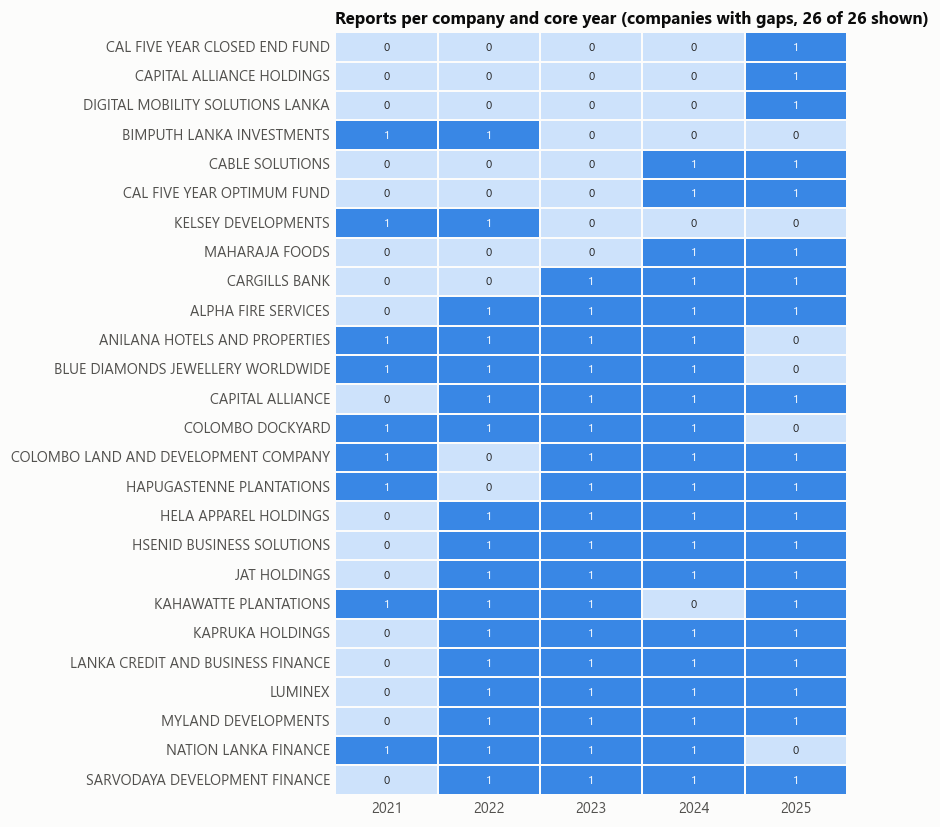

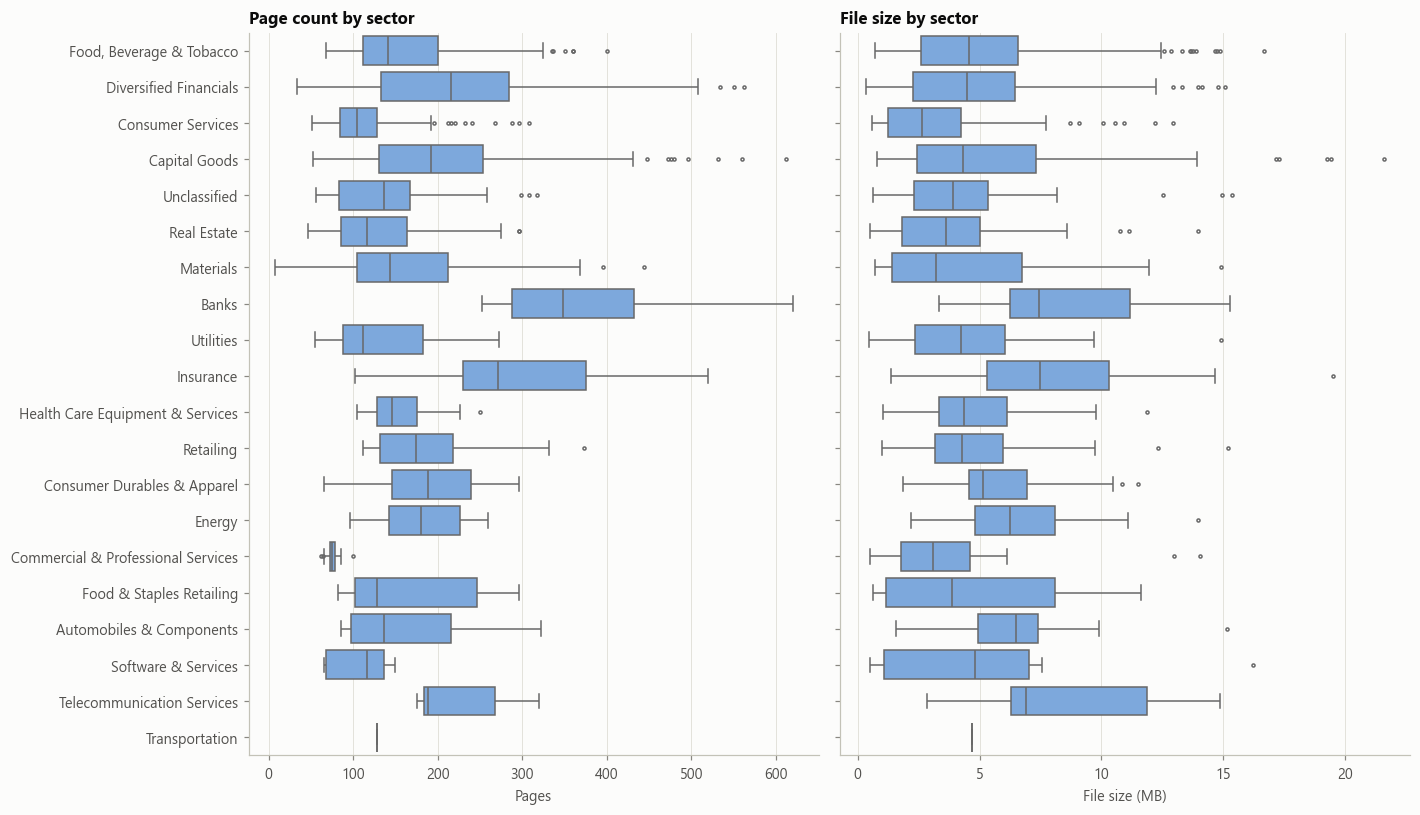

In [14]:
availability = pd.crosstab(screen["company"], screen["year"])
years = list(availability.columns)
core_years = [y for y in years if y in CORE_YEARS]
complete = (availability[core_years] > 0).all(axis=1)
outside = {int(y): int(availability[y].sum()) for y in years if y not in core_years}
print(f"{len(availability)} companies; {complete.sum()} have a report for every core year {core_years[0]}-{core_years[-1]}; "
      f"{(~complete).sum()} miss at least one; {(availability > 1).any(axis=1).sum()} have two reports for the same year; "
      f"reports outside the core years: {outside}")
gaps = availability[~complete].assign(missing=lambda d: (d[core_years] == 0).sum(axis=1)).sort_values(["missing", "company"], ascending=[False, True])
shown = gaps.head(80)[core_years]
if not shown.empty:
    plots.heatmap(shown, f"Reports per company and core year (companies with gaps, {len(shown)} of {len(gaps)} shown)", fmt="d", vmax=2, colorbar=False)
plt.show()
availability.to_csv(EDA_DIR / "company_year_availability.csv")
fig, axes = plt.subplots(1, 2, figsize=(13, 0.3 * len(SECTOR_ORDER) + 1.5), sharey=True)
for ax, column, label in [(axes[0], "page_count", "Pages"), (axes[1], "file_size_mb", "File size (MB)")]:
    sns.boxplot(data=screen, y="gics_group", x=column, order=SECTOR_ORDER, color=plots.SEQUENTIAL_STEPS[2], linewidth=1, fliersize=2, ax=ax)
    ax.set_xlabel(label)
    ax.set_ylabel("")
axes[0].set_title("Page count by sector")
axes[1].set_title("File size by sector")
plt.tight_layout()
plt.show()

## 9. B2 Report and section size

Size is measured in pages and in words of the PDF text layer. Every page is also labelled:

- **financial statements**: inside a located statement, notes or auditor's report section;
- **narrative target**: inside a located chairman's message, management discussion, risk, governance or sustainability section;
- **photo page**: images cover at least half of the page and it has fewer than 80 words;
- **low-value**: AGM notices, proxy forms, corporate profiles, milestones, board and management profiles, glossaries;
- **other**: everything else (strategy, capitals, value creation and similar content not on the target list).

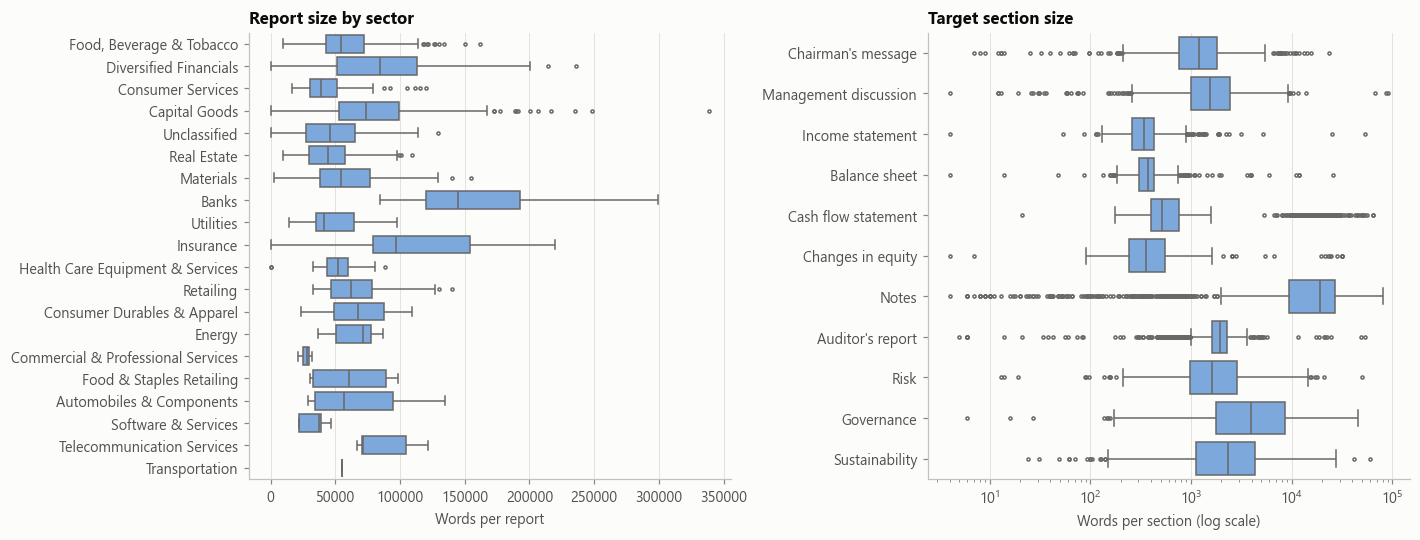

,median pages,median words
section,,
Chairman's message,2,1193
Management discussion,3,1555
Income statement,1,344
Balance sheet,1,370
Cash flow statement,2,517
Changes in equity,1,355
Notes,46,18985
Auditor's report,4,1958
Risk,4,1608


In [15]:
report_words = pages.groupby("report_id")["words"].sum()
screen["words"] = screen["report_id"].map(report_words)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(data=screen, y="gics_group", x="words", order=SECTOR_ORDER, color=plots.SEQUENTIAL_STEPS[2], linewidth=1, fliersize=2, ax=axes[0])
axes[0].set_xlabel("Words per report")
axes[0].set_ylabel("")
axes[0].set_title("Report size by sector")
section_order_labels = [SECTION_LABELS[k] for k in TARGET_SECTIONS]
sns.boxplot(data=section_size.assign(label=section_size["section"].map(SECTION_LABELS)), y="label", x="words", order=section_order_labels,
            color=plots.SEQUENTIAL_STEPS[2], linewidth=1, fliersize=2, log_scale=True, ax=axes[1])
axes[1].set_xlabel("Words per section (log scale)")
axes[1].set_ylabel("")
axes[1].set_title("Target section size")
plt.tight_layout()
plt.show()
section_size.groupby("section")[["pages", "words"]].median().reindex(list(TARGET_SECTIONS)).rename(index=SECTION_LABELS).astype(int).rename(columns=lambda c: f"median {c}")

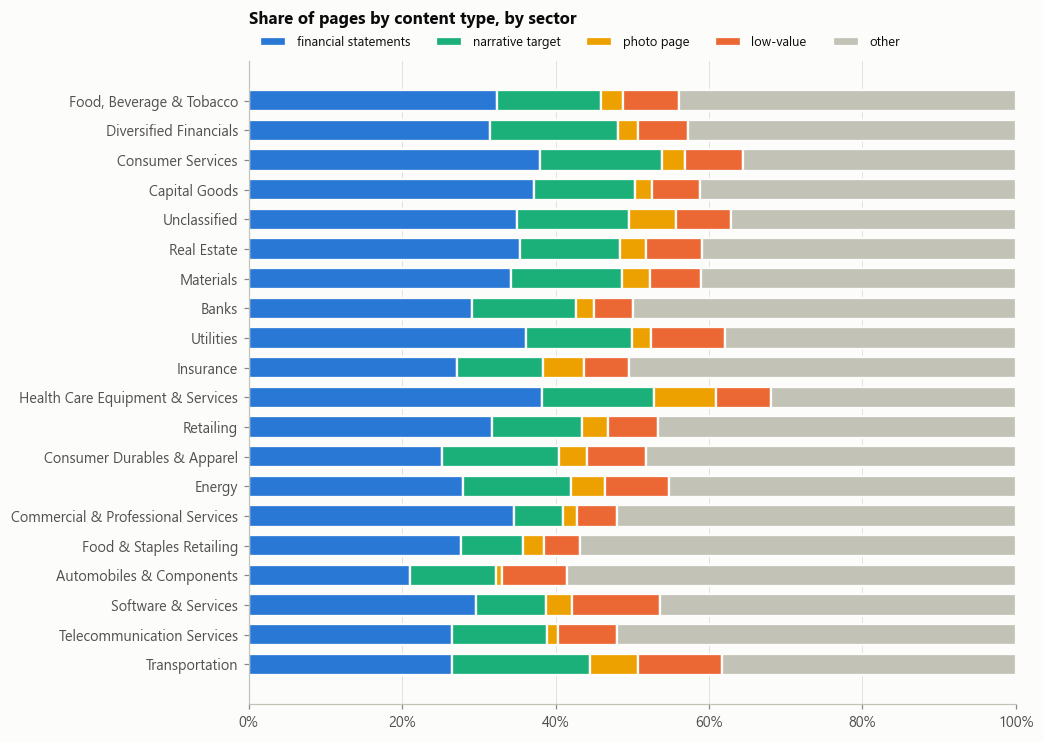

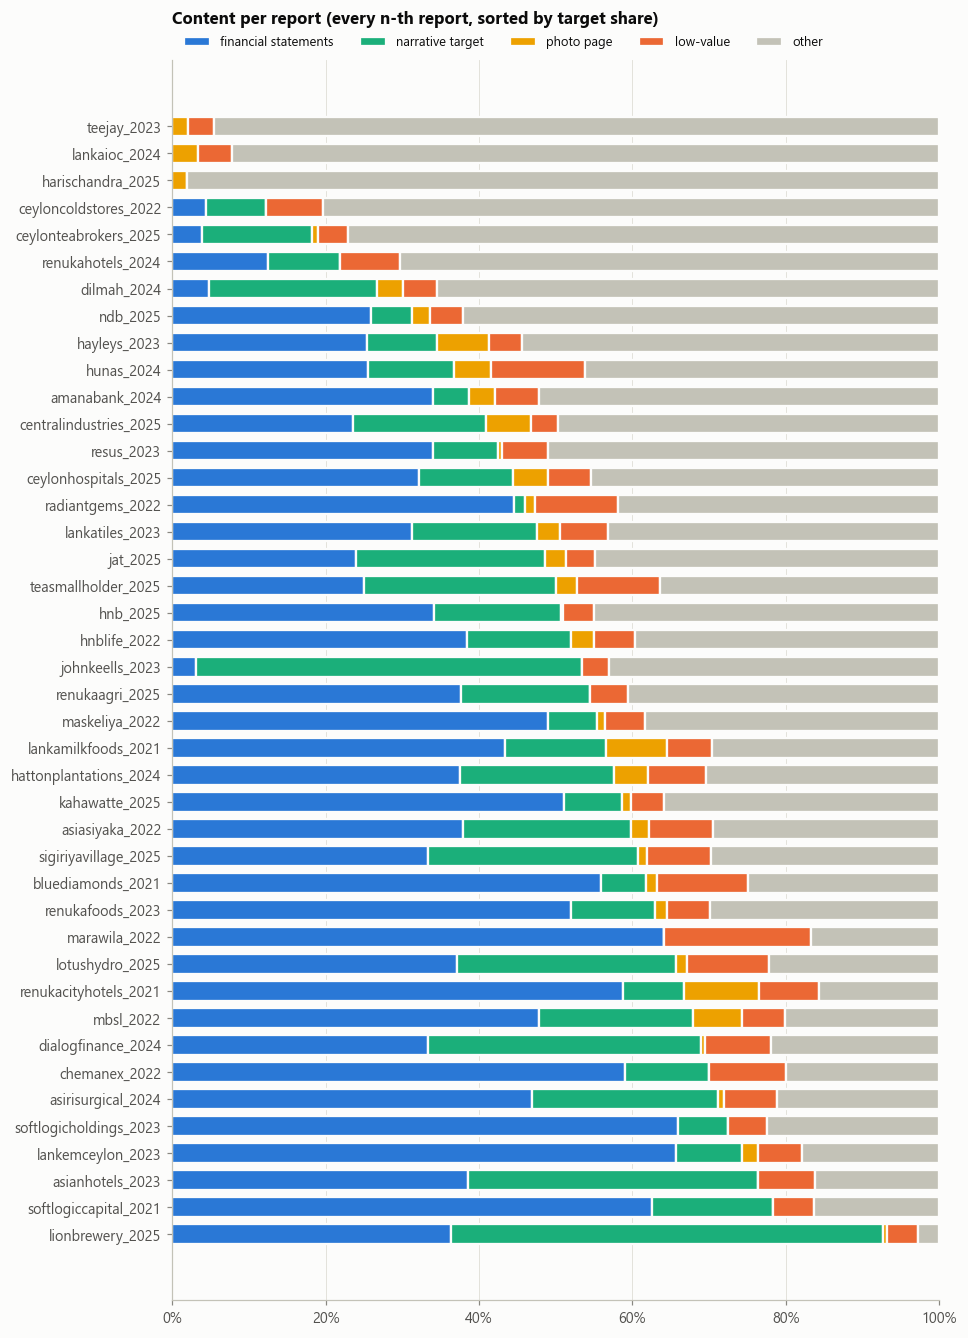

,value
Median share of pages in target sections,54%
Median share of photo and low-value pages,9%
Median share of other pages,35%


In [16]:
CATEGORY_COLORS = dict(zip(PAGE_CATEGORIES, [plots.CATEGORICAL[0], plots.CATEGORICAL[2], plots.CATEGORICAL[3], plots.CATEGORICAL[1], plots.INK["axis"]]))
category_pages = pd.crosstab(pages["gics_group"], pages["category"]).reindex(index=SECTOR_ORDER, columns=PAGE_CATEGORIES, fill_value=0)
plots.stacked_share(category_pages, CATEGORY_COLORS, "Share of pages by content type, by sector")
plt.show()
per_report = pd.crosstab(pages["report_id"], pages["category"]).reindex(columns=PAGE_CATEGORIES, fill_value=0)
per_report_share = per_report.div(per_report.sum(axis=1), axis=0)
target_share = per_report_share["financial statements"] + per_report_share["narrative target"]
low_share = per_report_share["photo page"] + per_report_share["low-value"]
sample = per_report.loc[target_share.sort_values().index[:: max(1, len(per_report) // 40)]]
plots.stacked_share(sample, CATEGORY_COLORS, "Content per report (every n-th report, sorted by target share)")
plt.show()
pd.Series({
    "Median share of pages in target sections": f"{target_share.median():.0%}",
    "Median share of photo and low-value pages": f"{low_share.median():.0%}",
    "Median share of other pages": f"{per_report_share['other'].median():.0%}",
}, name="value").to_frame()

## 10. B3 Table characteristics

Table sizes, multi-page tables and table density per section come from Docling. A table counts as **multi-page** when Docling already spans it across pages, or when it starts on the next page after a table with the same first row (or the same column count on a page marked "continued"). Those tables need stitching before chunking.

Without Docling output, only the stand-in density is shown: the share of section pages with at least 20 formatted figures.

**No Docling output found**, so table sizes and multi-page tables are not available yet.

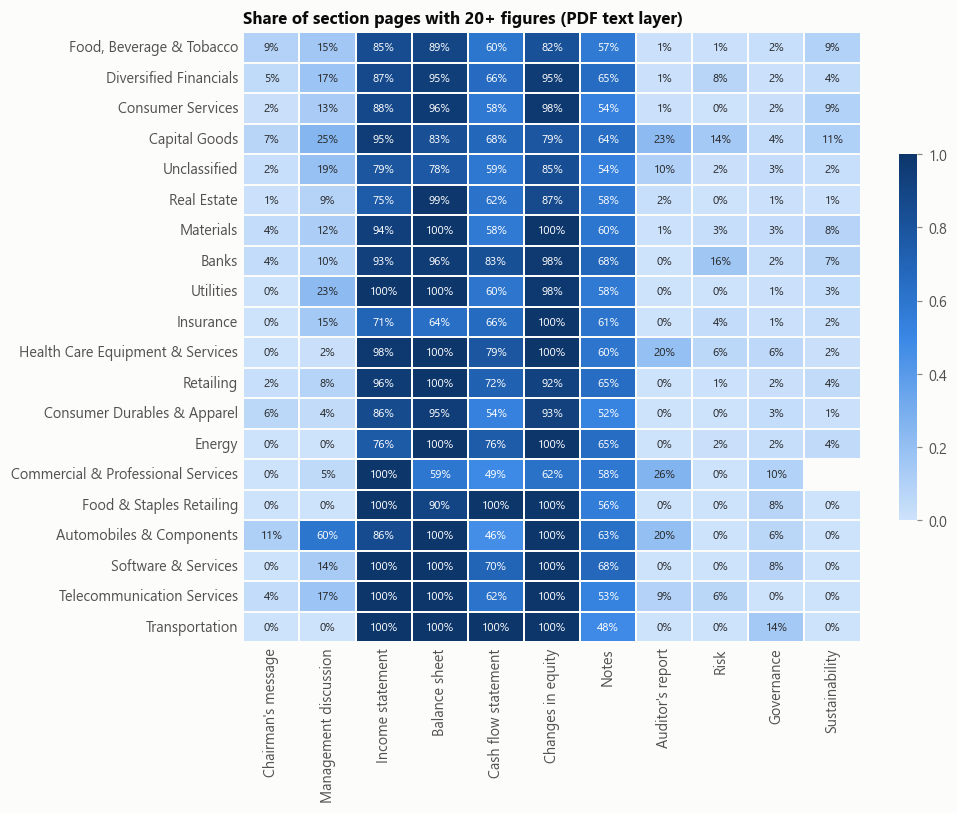

In [17]:
if HAS_DOCLING and not tables.empty:
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
    axes[0].hist(tables["rows"].clip(upper=80), bins=40, color=plots.CATEGORICAL[0])
    axes[0].set_xlabel("Rows (80+ grouped)")
    axes[0].set_title("Table rows")
    axes[1].hist(tables["cols"].clip(upper=15), bins=range(1, 17), color=plots.CATEGORICAL[0], rwidth=0.85)
    axes[1].set_xlabel("Columns (15+ grouped)")
    axes[1].set_title("Table columns")
    for ax in axes:
        ax.set_ylabel("Tables")
        ax.grid(axis="x", visible=False)
    plt.tight_layout()
    plt.show()
    multi = (tables["pages"].map(len) > 1) | tables["continues"]
    print(f"{len(tables):,} Docling tables in {tables['report_id'].nunique()} reports; {multi.sum():,} ({multi.mean():.1%}) are multi-page "
          f"({(tables['pages'].map(len) > 1).sum()} spanned by Docling, {tables['continues'].sum()} continued on the next page)")
    density_sums = section_density.dropna(subset=["tables"]).groupby(["gics_group", "section"])[["tables", "pages"]].sum()
    density = (density_sums["tables"] / density_sums["pages"]).unstack().reindex(index=[s for s in SECTOR_ORDER if s in density.index.get_level_values(0)], columns=list(TARGET_SECTIONS)).rename(columns=SECTION_LABELS)
    plots.heatmap(density, "Docling tables per page, by section and sector", fmt=".1f", vmax=None)
    plt.show()
else:
    display(Markdown("**No Docling output found**, so table sizes and multi-page tables are not available yet."))
proxy_sums = section_density.groupby(["gics_group", "section"])[["figure_pages", "pages"]].sum()
proxy = (proxy_sums["figure_pages"] / proxy_sums["pages"]).unstack()
proxy = proxy.reindex(index=SECTOR_ORDER, columns=list(TARGET_SECTIONS)).rename(columns=SECTION_LABELS)
plots.heatmap(proxy, "Share of section pages with 20+ figures (PDF text layer)", vmax=1)
plt.show()

## 11. B4 Fixed-size chunking damage

Naive chunking is simulated by cutting each report's reading-order text into fixed windows of 200, 400 and 800 words (roughly 256, 512 and 1,024 tokens). Counted per chunk size:

- **paragraphs split**: text blocks of 5 or more words cut across a chunk boundary;
- **tables split**: tables of 2 or more rows cut across a boundary;
- **rows cut off from their header**: table rows that land in a later chunk than the table's column headers, so the chunk holding them has no column names.

Docling elements are used when available. Otherwise PDF text blocks stand in: consecutive figure-heavy blocks on a page are treated as one table. Many of those stand-in "tables" are small KPI tiles rather than full statements, so the PDF-block figures **understate** table damage; the two sources are shown separately, and the Docling numbers are the ones to quote.

This single pass over all the text also gathers the inputs for B5 and B6. It takes a few minutes.

297/1190


594/1190


891/1190


1188/1190


1190/1190


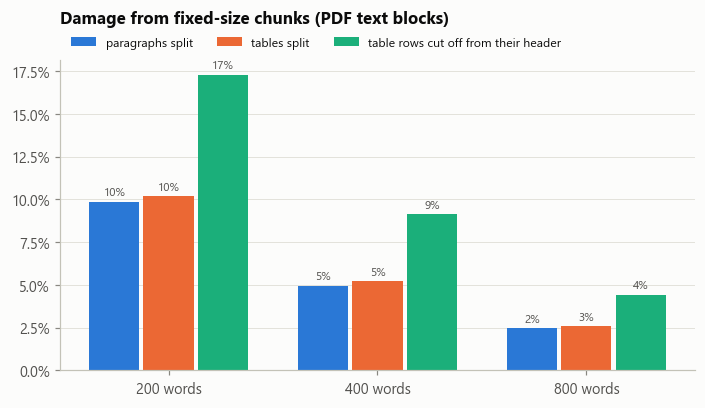

paragraphs  paragraphs_split  tables  tables_split  table_rows  rows_orphaned
element_source chunk_size                                                                               
pdf_blocks     200            3350496            330717  262218         26718     3785367         654524
               400            3350496            165585  262218         13638     3785367         346002
               800            3350496             82712  262218          6799     3785367         167373

In [18]:
text = text_pass(meta, sections, CACHE_DIR, docling_for, progress=show_progress)
damage = text["chunking"].groupby(["element_source", "chunk_size"]).sum(numeric_only=True)
rates = pd.DataFrame({
    "paragraphs split": damage["paragraphs_split"] / damage["paragraphs"],
    "tables split": damage["tables_split"] / damage["tables"],
    "table rows cut off from their header": damage["rows_orphaned"] / damage["table_rows"],
})
sources = list(rates.index.get_level_values(0).unique())
fig, axes = plt.subplots(1, len(sources), figsize=(6.5 * len(sources), 3.8), squeeze=False, sharey=True)
width = 0.26
for ax, source in zip(axes[0], sources):
    subset = rates.loc[source]
    x = np.arange(len(subset))
    for i, (column, color) in enumerate(zip(subset.columns, plots.CATEGORICAL)):
        bars = ax.bar(x + (i - 1) * width, subset[column], width=width - 0.02, color=color, label=column)
        ax.bar_label(bars, labels=[f"{v:.0%}" for v in subset[column]], padding=2, fontsize=7.5, color=plots.INK["secondary"])
    ax.set_xticks(x, [f"{size} words" for size in subset.index])
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
    ax.grid(axis="x", visible=False)
    ax.set_title(f"Damage from fixed-size chunks ({'Docling elements' if source == 'docling' else 'PDF text blocks'})", pad=24)
    ax.legend(ncols=3, loc="lower left", bbox_to_anchor=(0, 1.0), fontsize=8)
plt.tight_layout()
plt.show()
display(damage.astype(int))

In [19]:
for example in text["split_examples"]:
    header = "\n".join(example["header"])
    before = "\n".join(example["before"])
    after = "\n".join(example["after"])
    display(Markdown(f"**{example['report_id']}, page {example['page']}** ({example['element_source']}), cut by a {EXAMPLE_CHUNK_SIZE}-word chunk boundary\n\n"
                     f"```text\n{header}\n...\n{before}\n──────── chunk boundary ────────\n{after}\n```\n\n"
                     f"The rows after the boundary reach the next chunk without the header above."))

**annual-report-2021, page 16** (pdf_blocks), cut by a 400-word chunk boundary

```text
Revenue
...
2,276,181
2,671,470
Profit Before Income Tax & VAT
Rs. '000
──────── chunk boundary ────────
2,393,716
175.8%
867,807
1,213,472
```

The rows after the boundary reach the next chunk without the header above.

**abans-plc-annual-report-2021-22, page 10** (pdf_blocks), cut by a 400-word chunk boundary

```text
Revenue
...
3,650,982
3,111,048
17.36%
2,276,181
──────── chunk boundary ────────
Profit Before Income Tax & VAT
LKR'000
3,279,421
2,549,957
```

The rows after the boundary reach the next chunk without the header above.

**abans-plc-annual-report-2022-23, page 64** (pdf_blocks), cut by a 400-word chunk boundary

```text
Group                                                                          Company
...
3,956,533,579
3,144,632,488
3,235,080,062
Value Added Tax on Financial Services
──────── chunk boundary ────────
(153,698,847)
(131,898,880)
(4,432,103)
(7,195,603)
```

The rows after the boundary reach the next chunk without the header above.

## 12. B5 Boilerplate and repetition

1. **Within a company across years**: the same target section in consecutive years, compared with the Jaccard similarity of 5-word shingles (1 means identical text).
2. **Across companies**: text blocks of 25 or more words that appear word for word (digits ignored) in many companies' reports. These are candidate filter rules; the full list is saved to `data/eda/boilerplate_passages.csv`.
3. **Numeric density**: formatted figures per word in each section, which separates figure-heavy from narrative sections.

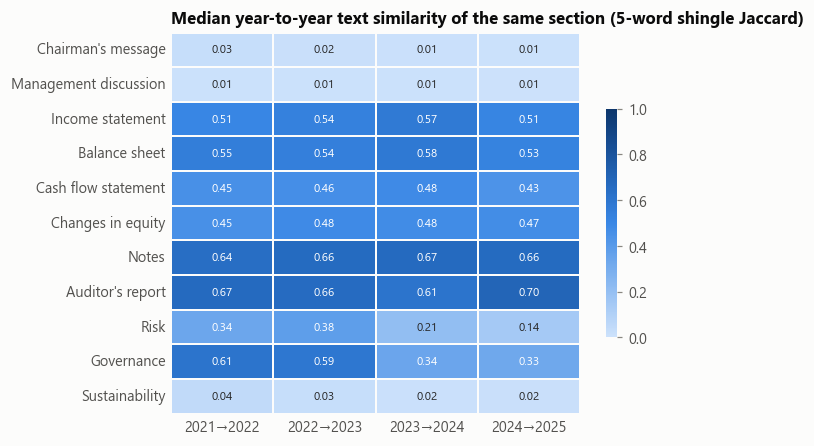

,count,25%,50%,75%
section,,,,
Chairman's message,691.0,0.01,0.02,0.06
Management discussion,629.0,0.00,0.01,0.05
Income statement,798.0,0.37,0.53,0.70
Balance sheet,793.0,0.40,0.55,0.72
Cash flow statement,797.0,0.22,0.46,0.64
Changes in equity,774.0,0.32,0.47,0.60
Notes,697.0,0.22,0.66,0.73
Auditor's report,734.0,0.45,0.66,0.79
Risk,616.0,0.04,0.27,0.65


In [20]:
similarity = text["similarity"]
similarity = similarity[similarity["to_year"].isin(CORE_YEARS)] if not similarity.empty else similarity
if similarity.empty:
    display(Markdown("No consecutive-year section pairs were found."))
else:
    similarity = similarity.assign(pair=similarity["from_year"].astype(int).astype(str) + "→" + similarity["to_year"].astype(int).astype(str))
    year_to_year = similarity.pivot_table(index="section", columns="pair", values="similarity", aggfunc="median")
    year_to_year = year_to_year.reindex([k for k in TARGET_SECTIONS if k in year_to_year.index]).rename(index=SECTION_LABELS)
    plots.heatmap(year_to_year, "Median year-to-year text similarity of the same section (5-word shingle Jaccard)", fmt=".2f", vmax=1)
    plt.show()
    display(similarity.groupby("section")["similarity"].describe()[["count", "25%", "50%", "75%"]].reindex(list(TARGET_SECTIONS)).rename(index=SECTION_LABELS).round(2))

In [21]:
company_count = meta["company"].nunique()
min_companies = max(5, round(0.03 * company_count))
boilerplate = pd.DataFrame(text["passages"].repeated(min_companies), columns=["companies", "words", "text"])
boilerplate.to_csv(EDA_DIR / "boilerplate_passages.csv", index=False)
print(f"{len(boilerplate)} passages appear word for word in at least {min_companies} of {company_count} companies")
boilerplate.head(25).assign(text=lambda d: d["text"].str.slice(0, 220))

1439 passages appear word for word in at least 7 of 247 companies


,companies,words,text
0,228,36,"We communicate with those charged with governance regarding, among other matters, the planned scope and timing of th..."
1,208,92,"From the matters communicated with those charged with governance, we determine those matters that were of most signi..."
2,201,33,"• Evaluate the overall presentation, structure and content of the financial statements, including the disclosures, a..."
3,200,45,"As required by section 163 (2) of the Companies Act, No. 07 of 2007, we have obtained all the information and explan..."
4,196,52,Management is responsible for the preparation of financial statements that give a true and fair view in accordance w...
5,190,103,Our objectives are to obtain reasonable assurance about whether the financial statements as a whole are free from ma...
6,186,78,"• Identify and assess the risks of material misstatement of the financial statements, whether due to fraud or error,..."
7,184,51,We also provide those charged with governance with a statement that we have complied with relevant ethical requireme...
8,180,51,We also provide those charged with governance with a statement that we have complied with ethical requirements in ac...
9,154,82,"In connection with our audit of the financial statements, our responsibility is to read the other information and, i..."


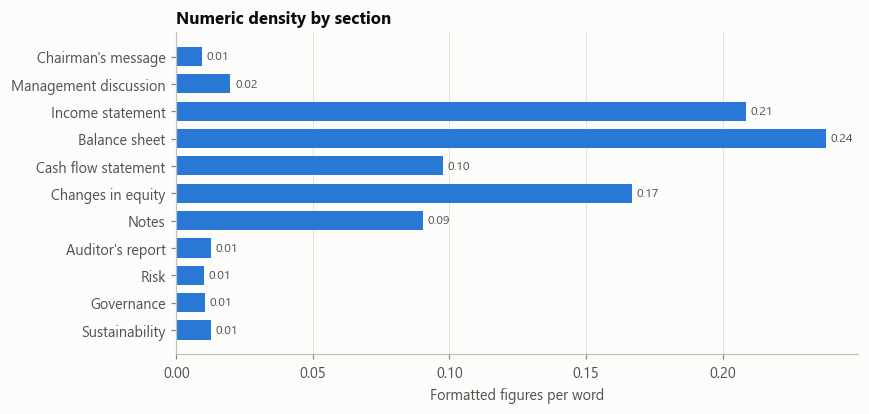

In [22]:
numeric_density = section_size.groupby("section")[["numbers", "words"]].sum()
numeric_density = (numeric_density["numbers"] / numeric_density["words"]).reindex(list(TARGET_SECTIONS)).rename(index=SECTION_LABELS)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(numeric_density.index, numeric_density.values, color=plots.CATEGORICAL[0], height=0.7)
ax.bar_label(ax.containers[0], labels=[f"{v:.2f}" for v in numeric_density.values], padding=3, fontsize=8, color=plots.INK["secondary"])
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("Formatted figures per word")
ax.set_title("Numeric density by section")
plt.show()

## 13. B6 Vocabulary and terminology

Words and two-word phrases are counted per sector (stop words and generic report words removed), then ranked with a TF-IDF-like weight, `p × log(p / q)`, where `p` is the term's share in the sector and `q` its share in the whole corpus. A term scores high when it is frequent in one sector and rarer elsewhere; terms used at the same rate everywhere ("financial", "board") score zero. Only terms used by at least a quarter of a sector's companies (and at least two) are ranked, so one company's name cannot top its sector. The top terms per sector are saved to `data/eda/sector_terms.csv` as input for the section-specific prompts and the coverage checklist.

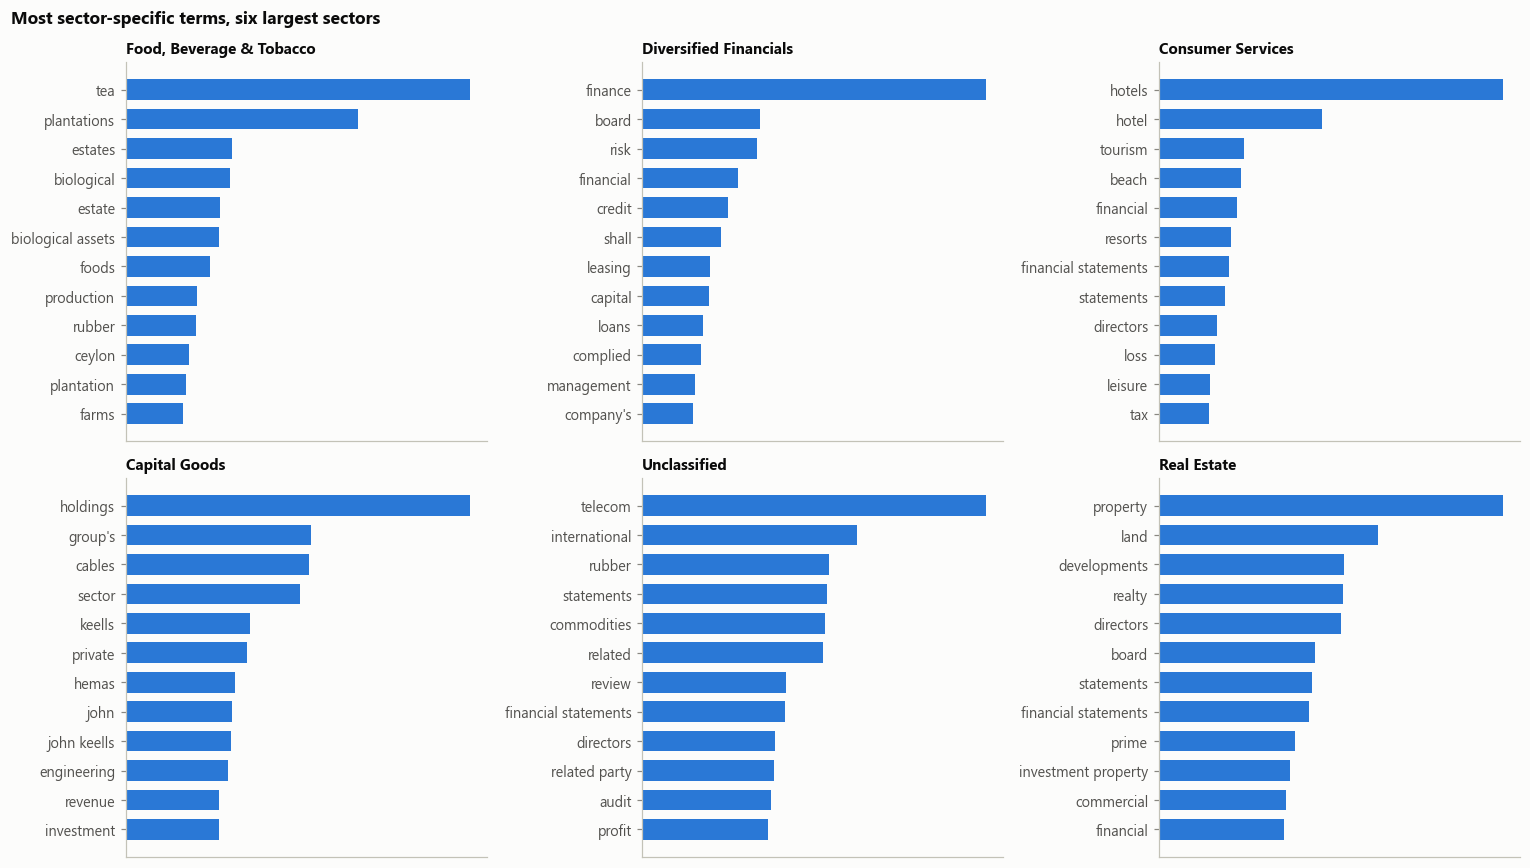

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29
most frequent term overall,financial,management,board,risk,value,assets,directors,committee,statements,financial statements,business,fair,income,director,bank,capital,audit,governance,related,tax,information,cash,loss,fair value,statement,cost,asset,profit,market,liabilities
count,615178,296736,294265,271102,261836,250861,248313,235635,223447,213499,170946,155123,150592,150235,147410,142202,141841,140969,138155,136085,134886,130690,130681,129917,119519,118032,117265,115191,111076,110697


,top 10 terms
gics_group,
"Food, Beverage & Tobacco","tea, plantations, estates, biological, estate, biological assets, foods, production, rubber, ceylon"
Diversified Financials,"finance, board, risk, financial, credit, shall, leasing, capital, loans, complied"
Consumer Services,"hotels, hotel, tourism, beach, financial, resorts, financial statements, statements, directors, loss"
Capital Goods,"holdings, group's, cables, sector, keells, private, hemas, john, john keells, engineering"
Unclassified,"telecom, international, rubber, statements, commodities, related, review, financial statements, directors, related p..."
Real Estate,"property, land, developments, realty, directors, board, statements, financial statements, prime, investment property"
Materials,"tiles, aluminium, haycarb, ceramics, products, packaging, royal ceramics, royal, porcelain, dipped"
Banks,"bank, bank's, banking, risk, credit, dfcc, dfcc bank, banks, risk management, sampath"
Utilities,"power, energy, hydro, solar, hydro power, project, renewable, lotus, renewable energy, laugfs"


In [23]:
sector_companies = meta.groupby("gics_group")["company"].nunique()
shared_terms = {g: {t for t, n in counts.items() if n >= max(2, 0.25 * sector_companies[g])} for g, counts in text["term_companies"].items()}
ranked = distinctive_terms(text["terms"], top_n=20, allowed=shared_terms)
sector_terms = pd.DataFrame([{"gics_group": g, "rank": i + 1, "term": t, "score": s} for g, terms in ranked.items() for i, (t, s) in enumerate(terms)])
sector_terms.to_csv(EDA_DIR / "sector_terms.csv", index=False)
shown_sectors = [s for s in SECTOR_ORDER if ranked.get(s)][:6]
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, sector in zip(axes.flat, shown_sectors):
    terms = ranked[sector][:12]
    ax.barh([t for t, _ in terms], [s for _, s in terms], color=plots.CATEGORICAL[0], height=0.7)
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
    ax.set_xticks([])
    ax.set_title(sector, fontsize=10)
for ax in list(axes.flat)[len(shown_sectors):]:
    ax.set_visible(False)
fig.suptitle("Most sector-specific terms, six largest sectors", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()
overall = Counter()
for counts in text["terms"].values():
    overall.update(counts)
display(pd.DataFrame(overall.most_common(30), columns=["most frequent term overall", "count"]).T)
sector_terms[sector_terms["rank"] <= 10].groupby("gics_group")["term"].apply(", ".join).reindex(SECTOR_ORDER).dropna().to_frame("top 10 terms")

## 14. B7 Consistency over time

For each company, consecutive reports are compared on structure source, bookmark presence, the order of the target sections, the overlap of section headings and page count. A pair is flagged as a **layout change** when the structure source changes, fewer than 70% of section pairs keep their order, fewer than 30% of headings carry over, or the page count changes by more than half. The full list is saved to `data/eda/layout_changes.csv`.

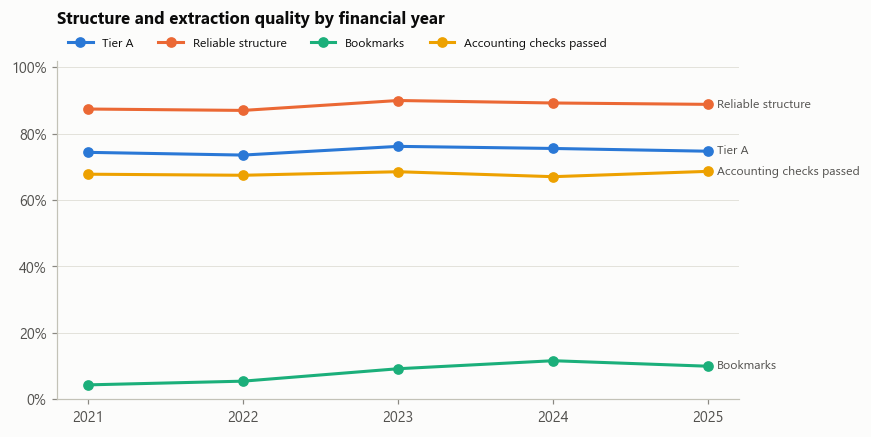

943 consecutive report pairs; 273 (29%) show a layout change


,pairs
change_reasons,
headings renamed,200
structure none to contents_page,48
structure contents_page to none,46
structure contents_page to bookmarks,37
structure bookmarks to contents_page,27
page count x...,24
structure none to bookmarks,13
structure bookmarks to none,11
section order changed,8


,company,from_year,to_year,order_agreement,heading_overlap,page_ratio,change_reasons
0,ABANS,2021,2022,1.000000,0.156863,0.698413,headings renamed
4,ACCESS ENGINEERING,2021,2022,1.000000,0.181159,2.037267,structure none to contents_page; headings renamed; page count x2.04
16,AGALAWATTE PLANTATIONS,2021,2022,1.000000,0.447368,1.034483,structure contents_page to none
17,AGALAWATTE PLANTATIONS,2022,2023,1.000000,0.421053,0.966667,structure none to contents_page
20,AGSTAR,2021,2022,1.000000,0.320000,1.028571,structure contents_page to none
21,AGSTAR,2022,2023,1.000000,0.375000,0.916667,structure none to contents_page
22,AGSTAR,2023,2024,1.000000,0.297872,1.060606,headings renamed
24,AITKEN SPENCE,2021,2022,0.933333,0.272727,1.164835,headings renamed
27,AITKEN SPENCE,2024,2025,0.666667,0.357895,1.127119,section order changed
28,ALLIANCE FINANCE,2021,2022,0.890909,0.147826,1.058824,structure contents_page to none; headings renamed


In [24]:
timeline = screen[["report_id", "company", "year", "structure_source", "has_bookmarks", "page_count", "tier"]].assign(
    section_order=[section_order(sections[rid]) for rid in screen["report_id"]],
    headings=[[s["title"] for s in profiles[rid]["segments"]] for rid in screen["report_id"]],
)
changes = layout_changes(timeline)
changes.to_csv(EDA_DIR / "layout_changes.csv", index=False)
by_year = core.groupby("year").agg(
    tier_a=("tier", lambda s: (s == "A").mean()),
    reliable_structure=("structure_source", lambda s: s.isin(["bookmarks", "contents_page"]).mean()),
    bookmarks=("has_bookmarks", "mean"),
    checks_passed=("accounting_checks_passed", "sum"),
    checks_run=("accounting_checks_run", "sum"),
)
by_year["checks_pass_rate"] = by_year["checks_passed"] / by_year["checks_run"]
series = {"Tier A": "tier_a", "Reliable structure": "reliable_structure", "Bookmarks": "bookmarks", "Accounting checks passed": "checks_pass_rate"}
fig, ax = plt.subplots(figsize=(8, 4))
for (label, column), color in zip(series.items(), plots.CATEGORICAL):
    ax.plot(by_year.index.astype(int), by_year[column], color=color, marker="o", label=label)
    ax.annotate(label, (by_year.index[-1], by_year[column].iloc[-1]), xytext=(6, 0), textcoords="offset points", va="center", fontsize=8, color=plots.INK["secondary"])
ax.set_xticks(by_year.index.astype(int))
ax.set_ylim(0, 1.02)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.grid(axis="x", visible=False)
ax.set_title("Structure and extraction quality by financial year", pad=24)
ax.legend(ncols=4, loc="lower left", bbox_to_anchor=(0, 1.0), fontsize=8)
plt.show()
print(f"{len(changes)} consecutive report pairs; {changes['layout_changed'].sum()} ({changes['layout_changed'].mean():.0%}) show a layout change")
display(changes["change_reasons"].str.split("; ").explode().replace("", np.nan).dropna().str.replace(r"x\d.*", "x...", regex=True).value_counts().to_frame("pairs"))
changes[changes["layout_changed"]].sort_values(["company", "to_year"])[["company", "from_year", "to_year", "order_agreement", "heading_overlap", "page_ratio", "change_reasons"]].head(30)

---
## 15. Summary of findings

The table below restates the main numbers from this run next to the pipeline decision each one informs.

In [25]:
tier_share = screen["tier"].value_counts(normalize=True)
rates_400_all = rates.xs(400, level="chunk_size") if 400 in rates.index.get_level_values("chunk_size") else pd.DataFrame()
rates_source = "docling" if "docling" in rates_400_all.index else (rates_400_all.index[0] if len(rates_400_all) else None)
rates_400 = rates_400_all.loc[rates_source] if rates_source else None
reused = similarity.groupby("section")["similarity"].median() if not similarity.empty else pd.Series(dtype=float)
most_reused = ", ".join(SECTION_LABELS[k] for k in reused.sort_values(ascending=False).index[:3]) if len(reused) else "n/a"
findings = [
    ("Text-based screening", f"{(screen['text_status'] == 'fail').sum()} scanned reports; {(screen['text_status'] == 'partial').sum()} with some image-only pages", "Which reports enter the dataset"),
    ("Structure source", ", ".join(f"{k}: {v:.0%}" for k, v in screen["structure_source"].value_counts(normalize=True).items()), "Which heading source the chunker uses, and when fallback rules apply"),
    ("Section coverage", f"median {screen['section_coverage'].median():.0f} of {len(TARGET_SECTIONS)} targets found; {len(unmatched_table)} distinct unmatched headings to review", "Section detection rules and the synonym map"),
    ("Image statements", f"{screen['image_statement_flag'].sum()} reports with a statement that looks like an image", "Which reports are excluded from figure extraction"),
    ("Extraction correctness", ", ".join(f"{k}: {int(v['pass'])}/{int(v.sum())} pass" for k, v in outcome_table.iterrows()), "Docling configuration and number parsing rules"),
    ("Tiers", f"A {tier_share.get('A', 0):.0%}, B {tier_share.get('B', 0):.0%}, C {tier_share.get('C', 0):.0%} ({included} reports enter the pipeline)", "Main pipeline vs fallback rules vs exclusion"),
    ("Multi-page tables", f"{multi.mean():.1%} of Docling tables" if HAS_DOCLING and not tables.empty else "needs Docling output", "Table stitching before chunking"),
    ("Fixed-size chunking damage", f"at 400 words: {rates_400['paragraphs split']:.0%} of paragraphs split, {rates_400['tables split']:.0%} of tables split, {rates_400['table rows cut off from their header']:.0%} of table rows lose their header ({'Docling' if rates_source == 'docling' else 'PDF text blocks, understates tables'})" if rates_400 is not None else "n/a", "Evidence for the structure-aware approach"),
    ("Boilerplate", f"{len(boilerplate)} passages repeated across {min_companies}+ companies; most reused sections year to year: {most_reused}", "Low-value chunk filtering"),
    ("Vocabulary", f"top terms for {len(ranked)} sectors saved to sector_terms.csv", "Section-specific prompts and the coverage checklist"),
    ("Consistency over time", f"{changes['layout_changed'].mean():.0%} of consecutive report pairs change layout", "Fallback rules for older layouts"),
]
pd.DataFrame(findings, columns=["EDA finding", "This run", "Pipeline decision"]).style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "pre-wrap"})

EDA finding,This run,Pipeline decision
Text-based screening,9 scanned reports; 50 with some image-only pages,Which reports enter the dataset
Structure source,"contents_page: 80%, none: 12%, bookmarks: 8%","Which heading source the chunker uses, and when fallback rules apply"
Section coverage,median 10 of 11 targets found; 6343 distinct unmatched headings to review,Section detection rules and the synonym map
Image statements,32 reports with a statement that looks like an image,Which reports are excluded from figure extraction
Extraction correctness,"Balance sheet identity (PDF layer, n=1190): 838/1190 pass, Subtotals (PDF layer, n=1190): 328/1190 pass, Profit cross-check (PDF layer, n=1190): 611/1190 pass, Highlights (PDF layer, n=1190): 689/1190 pass",Docling configuration and number parsing rules
Tiers,"A 75%, B 23%, C 2% (1166 reports enter the pipeline)",Main pipeline vs fallback rules vs exclusion
Multi-page tables,needs Docling output,Table stitching before chunking
Fixed-size chunking damage,"at 400 words: 5% of paragraphs split, 5% of tables split, 9% of table rows lose their header (PDF text blocks, understates tables)",Evidence for the structure-aware approach
Boilerplate,"1439 passages repeated across 7+ companies; most reused sections year to year: Auditor's report, Notes, Balance sheet",Low-value chunk filtering
Vocabulary,top terms for 20 sectors saved to sector_terms.csv,Section-specific prompts and the coverage checklist
